In [ ]:
https://www.sfu.ca/~mjbrydon/tutorials/BAinPy/01_intro.html
https://seaborn.pydata.org/examples/smooth_bivariate_kde.html

# Analiza efektywności wykorzystania systemów rowerów miejskich: metody statystyczne i wizualizacja danych
### Praca inżynierska na kierunku Analiza Danych

Marcin Bereza

Nr albumu: 402790

---

## Metodologia przetwarzania zbiorów

### Charakterystyka danych, ładowanie i łączenie zbiorów

#### OpenData.Wroclaw.pl
Opracowywane dane dotyczą wypożyczeń rowerów z okresu od 01.03.2019 do 31.12.2021 z systemu Wrocławski Rower Miejski pozyskanych ze strony: [**otwarte**danewrocław](https://opendata.cui.wroclaw.pl/dataset/przejazdy-wroclawskiego-roweru-miejskiego-archiwalne). Zestaw składa się z miesięcznych zapisów i zawiera poniższe kolumn:
- **UID wynajmu (ang. uid)** - unikatowy numer identyfikujący dane wypożyczenie. Ciąg znaków zawiera dziewięcio cyfrową roznącą liczbę. Obserwację nie zwiększają się o jeden, a o parę liczb. Może to sugerować wcześniejszą ingerencję w zestaw poprzez usunięcie niektórych rekordów. Kolumne można usunąć z dalszej analizy.

- **Numer roweru (ang. bike_number)** - unikatowy numer dla każdego z rowerów. Kod składa się z 5-6 cyfr. Umożliwia uzyskanie dodatkowych danych, takich jak: najbardziej eksploatowany rower, liczba rowerów w systemie. Prawdopodobieństwo, że dany rower nie został ani jeden raz wypożyczony w ciągu miesiąca jest znikomy.

- **Data wynajmu (ang. start_time)** - dokładna data dokonania wypożyczenia, przedstawiona w formacie: rok-miesiąc-dzień godzina:minuta:sekunda. W celach dalszej analizy należy rozdzielić kolumnę na odrębne składowe.

- **Data zwrotu (ang. end_time)** - dokładna data zwrócenia roweru, zapisana w takim samym formacie jak data wynajmu.

- **Stacja wynajmu (ang. rental_place)** - nazwa stacji, z której rozpoczęto trasę. Podana jako nazwa / skrzyżowanie ulic / charakterystyczny budynek. W celu wykorzystania tej informacji, należy wpierw ustalić długość i szerokość geograficzną takiej stacji. Umożliwiają to takie narzędzia jak: dostępne bazy danych, biblioteka geopy w Python, ręczne wyszukiwanie lokalizacji.

- **Stacja zwrotu (ang. return_place)** - nazwa stacji na które dokonano zakończenia podróży. Format tożsamy ze stacją wynajmu.

- **Czas trwania (ang. rental_time)** - czas przejazdu ze stacji wynajmu do stacji zwrotu podany w minutach. Lepszym rozwiązaniem będzie samodzielne wyliczenie czasu na podstawie dat wynajmu oraz zwrotu, pozyskanie go w taki sposób przyczyni się do poprawy precyzji danych. Domyślna inforamcji zawiera zaokrąglone liczby, a także ta seria danych rozpoczyna się od 2020 roku.

Zestaw po złączeniu wszystkich miesięcy i lat zawiera łącznie: 5 257 355 rekordów.

Posiłkując się oficjalnymi danymi we Wrocławiu na chwilę obecną funkcjonuje 230 stacji Wrocławkiego Roweru Miejskiego (1).

(1) https://www.wroclaw.pl/komunikacja/wroclawski-rower-miejski-stacje-nowe-kobierzyce-katy-wroclawskie-wisznia-mala

In [10]:
import pandas as pd
import numpy as np
import os

bike_files = [f for f in os.listdir('Przejazdy') if f.endswith('.csv')]
column_naming = {
    'UID wynajmu':      'uid',
    'Numer roweru':     'bike_number',
    'Data wynajmu':     'start_time',
    'Data zwrotu':      'end_time',
    'Stacja wynajmu':   'rental_place',
    'Stacja zwrotu':    'return_place'
}


datasets = []
for i, file in enumerate(bike_files):
    file_path = os.path.join('Przejazdy', file)
    
    with open(file_path, encoding='utf-8-sig') as f:
        ncols = len(f.readline().split(','))
    
    if '2019' in file:
        df = pd.read_csv(file_path, usecols=range(1,ncols))
    else:
        df = pd.read_csv(file_path, usecols=range(0,ncols-1))
    df.rename(columns=column_naming, inplace=True)
    datasets.append(df)
    
bike_dataset = pd.concat(datasets, ignore_index=True)

In [11]:
bike_dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5257355 entries, 0 to 5257354
Data columns (total 6 columns):
 #   Column        Dtype 
---  ------        ----- 
 0   uid           int64 
 1   bike_number   int64 
 2   start_time    object
 3   end_time      object
 4   rental_place  object
 5   return_place  object
dtypes: int64(2), object(4)
memory usage: 240.7+ MB


#### WrocławskiRower.pl
Kolejnym źródłem danych jest [Wrocławskirower.pl](https://wroclawskirower.pl/mapa-stacji/). Pozwoli ono na przeprowadzenie analizy przestrzennej. Wykorzystując narzędzie Microsoft'u PowerQuery, występujące w Excel'u oraz PowerBi, pobieramy i przekształcamy dane do wymaganego przez nas formatu. Końcowo mamy takie kolumny jak:
- Nazwę stacji
- Szerokość geograficzna
- Długość geograficzna

Zestaw zawiera lokalizację 240 stacji rowerów miejskich we Wrocławiu.

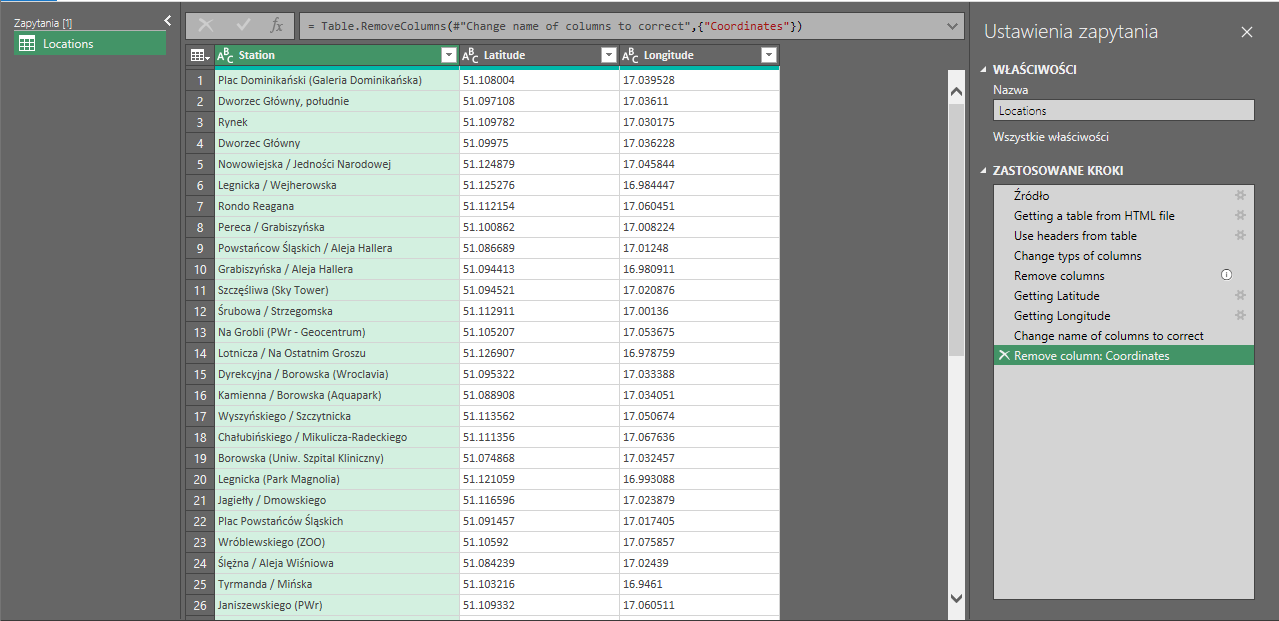

Dane aktualizowane są w trybie ciągłym, a z racji że interesują nas tylko położenie stacji, pozbywamy się informacji o:
- Aktualnej liczbie rowerów
- Numerów dostepnych rowerów
- Numeru stacji
- Liczby stojaków

Stron nie dostarcza jednak współrzędnych dla wszystkich stacji rowyerowych występujących w danych wypożyczeń.

Musimy mieć na względzie możliwość na przestrzeni lat:
- zmiany nazw ulic
- przeniesień stacji
- likwidację infrastruktury

 Z tego względu wykorzystamy bibliotekę geopy, a także manualne wyszukiwanie lokalizacji.

Ładujemy zbiór pozyskany ze strony: [Wroclawskirower.pl](https://wroclawskirower.pl/mapa-stacji/) przy wykorzystaniu web scrapingu.

In [12]:
geolocation = pd.read_excel('Lok.xlsx')
geolocation

,Station,Latitude,Longitude
0,Plac Dominikański (Galeria Dominikańska),51.108004,17.039528
1,"Dworzec Główny, południe",51.097108,17.036110
2,Rynek,51.109782,17.030175
3,Dworzec Główny,51.099750,17.036228
4,Nowowiejska / Jedności Narodowej,51.124879,17.045844
...,...,...,...
235,Bielany Wrocławskie Kolejowa P&R,51.037950,16.976374
236,Wysoka Nastrojowa,51.052835,17.003956
237,Mokronos Górny PKP,51.078886,16.908149
238,Smolec,51.087048,16.911286


### Transformacja danych, pozyskiwanie danych, uzyskiwnie nowych zmiennych
Identyfikacja punktów odstających ma kluczowe znaczenie dla przeprowadzenia rzetelnej
analizy danych systemu rowerów miejskich. Należy wyeliminować obserwacje, dla których
stacja początkowa lub końcowa to pozostawienie roweru poza stacją. Zazwyczaj czasy takich
wypożyczeń są długie, co może zniekształcać wyniki analizy.

Kolejnym problematycznym przypadkiem są wypożyczenia, które zaczęły się i zakończyły na tej samej stacji. Z perspektywy krótkiego czasu wypożyczenia, mogło to wynikać z
problemu technicznego, na przykład blokada roweru mogła się nie otworzyć. Z kolei wypożyczenia trwające dłużej mogły być jazdą testową lub rekreacyjną. Należy ustalić, jaka wartość
czasu wypożyczenia jest traktowana jako problematyczna, a powyżej jakiej ma być uznana
za prawidłową.

Czas wypożyczenia trwający bardzo długo może również wskazywać na jazdę testową
lub rekreacyjną. Konieczne jest ustalenie progu czasu wypożyczenia, który będzie uznawany
za anomalię. Na przykład, wypożyczenia trwające powyżej pewnego czasu (np. 8 godzin)
mogą być uznawane za anomalię, podczas gdy wypożyczenia trwające krócej będą uznawane
za prawidłowe. Ponieważ badamy wzorce użytkowników, dane dotyczące obsługi systemu,
takie jak bardzo długie wypożyczenia, należy porzucić, gdyż nie wnoszą wartości do analizy
użytkowania systemu.

Dodatkowo, brak danych odnośnie czasu wypożyczenia uniemożliwia obliczenie prędkości użytkownika i czasu trwania podróży. W takich przypadkach dane również należy odrzucić, ponieważ nie pozwalają one na pełną analizę wzorców użytkowania.

#### Selekcja obserwacji wypożyczeń rowerowych
Przed przystąpieniem do pozyskania brakujących danych, musimy ustandaryzować zapis stacji, t.z.:
- należy wyeliminować puste znaki, komplikujące połączenie tabel
- usunąć rekordy zaczynające się od kropki oraz hashtagu (są to m.in.: akcje serwisowe, rezerwacje, relokacja)
- wykluczyć rekordy, gdzie stacja początkowa jest tożsama ze stacją końcową (są to m.in: awarie systemu, problem z wypożyczeniem, uszkodzony rower, testowanie sposobu wypożyczenia), sprawia to również brak możliwości oszacowania przebytego dystansu, a także średniej prędkości przejazdu.
- wyłączenie obserwacji, których jako wartość stacji początkowej, bądz końcowej jest "Poza stacją" (nie jesteśmy wstanie ustalić nawet przybliżonej pozycji.)
- zamieniamy zapis na małe litery

Zamieniamy także zapis dat na format akceptowany dla pandas'a.

In [13]:
bike_dataset = bike_dataset.replace('\xa0', '', regex=True)
bike_dataset = bike_dataset.replace(' )', ')')
bike_dataset = bike_dataset.replace('( ', '(')

bike_dataset['rental_place'] = bike_dataset['rental_place'].map(lambda x: x.strip())
bike_dataset['rental_place'] = bike_dataset['rental_place'].map(lambda x: x.strip(','))
bike_dataset['rental_place'] = bike_dataset['rental_place'].map(lambda x: x.lower())

bike_dataset['return_place'] = bike_dataset['return_place'].map(lambda x: x.strip())
bike_dataset['return_place'] = bike_dataset['return_place'].map(lambda x: x.strip(','))
bike_dataset['return_place'] = bike_dataset['return_place'].map(lambda x: x.lower())

bike_dataset = bike_dataset[~bike_dataset['rental_place'].str.startswith('.')]
bike_dataset = bike_dataset[~bike_dataset['rental_place'].str.startswith('#')]
bike_dataset = bike_dataset[~bike_dataset['return_place'].str.startswith('.')]
bike_dataset = bike_dataset[~bike_dataset['return_place'].str.startswith('#')]

bike_dataset['start_time'] = pd.to_datetime(bike_dataset['start_time'])
bike_dataset['end_time'] = pd.to_datetime(bike_dataset['end_time'])

Wyodrębniamy rok z miesiącem dla każdego rekordu, aby umożliwić grupowanie rekordów, a także obliczamy czas trwania wypożyczenia.

In [14]:
bike_dataset['date'] = bike_dataset['start_time'].dt.strftime('%Y-%m')
bike_dataset['rental_time'] = round((bike_dataset.loc[:,'end_time'] - bike_dataset.loc[:,'start_time']).dt.total_seconds()/60, 2)

In [15]:
bike_dataset.describe()

,uid,bike_number,start_time,end_time,rental_time
count,5.248777e+06,5.248777e+06,5248777,5248777,5.248777e+06
mean,1.017817e+08,3.905253e+05,2020-08-02 08:47:49.163726848,2020-08-02 09:18:28.651205120,3.065813e+01
min,6.471978e+07,1.265300e+04,2019-02-20 12:15:34,2019-03-01 14:29:44,-5.950000e+01
25%,8.366494e+07,5.758200e+04,2019-08-30 17:51:58,2019-08-30 18:24:34,6.300000e+00
50%,1.027936e+08,6.501450e+05,2020-08-12 16:42:46,2020-08-12 17:03:19,1.072000e+01
75%,1.195302e+08,6.507360e+05,2021-06-19 00:59:59,2021-06-19 01:23:39,1.670000e+01
max,1.353896e+08,8.528530e+05,2021-12-31 23:50:29,2021-12-31 23:58:36,2.469754e+05
std,1.997904e+07,2.943480e+05,NaN,NaN,7.054189e+02


Jak widać mamy do czynienia nie tylko z podróżami w przestrzeni, a także w czasie. Odrazu wyeliminujemy takie obserwacje.

In [16]:
bike_dataset = bike_dataset[bike_dataset['rental_time']>0]

Sprawdźmy ile jest rekordów, które zaczeły / zakończyły się w nieznanej lokalizacji. W tym celu tworzymy jeden zbiór zawierający wyłączenie rekordy z zapisami "Poza stacją", a także osobny zbiór bez takich danych.

In [17]:
bike_undefied = bike_dataset[(bike_dataset.loc[:,'rental_place'] == 'poza stacją') | (bike_dataset.loc[:,'return_place']  == 'poza stacją')]
bike_dataset2 = bike_dataset[~((bike_dataset.loc[:,'rental_place'] == 'poza stacją') | (bike_dataset.loc[:,'return_place']  == 'poza stacją'))]

Grupujemy dane po dacie i sumujemy liczbę obserwacji dla utworzonych zestawów danych w *tysiącach*. Przy łączeniu tak otrzymanych tabel musimy zadbać o poprawnę ich złączenie. Wyberamy tryb łączenia zewnętrzny (t.z. każdy rekord bedzie uwzgledniony w zestwieniu) i uzupełniamy brakujące rekordy o wartość zerową.

In [18]:
bike_leave = pd.DataFrame(bike_undefied.groupby(['date']).size().reset_index())
bike_leave.columns=['date', 'leave_bikes']

bike_standard = pd.DataFrame(bike_dataset2.groupby(['date']).size().reset_index())
bike_standard.columns=['date', 'rental_bikes']

bike_chart = bike_leave.merge(bike_standard, how='outer', on='date')
bike_chart['leave_bikes'] = bike_chart['leave_bikes']/1000
bike_chart['rental_bikes'] = bike_chart['rental_bikes']/1000
bike_chart = bike_chart.fillna(0)

Tworzymy zestawienie obrazujące korelację pozostawionych rowerów od wypożyczonych, a także wyświetlamy dane na histogramie.

Po poniższych wykresów możemy stwierdzić, że korelacja danych wynosi niemal jeden, co oznacza że liczba pozostawionych rowerów rośnie liniowo wraz ze wzrostem liczby wypożyczeń. Sugeruje to możliwość usunięcia problematycznych danych, bo występują one naturalnie w zbiorze danych, nie są to celowe zmiany danych, ani losowe. Brak lokalizacji wynajęcia i zwrotu może wynikać z pozostawienia poza stacją, problemem ze zwrotem, awarią systemu.

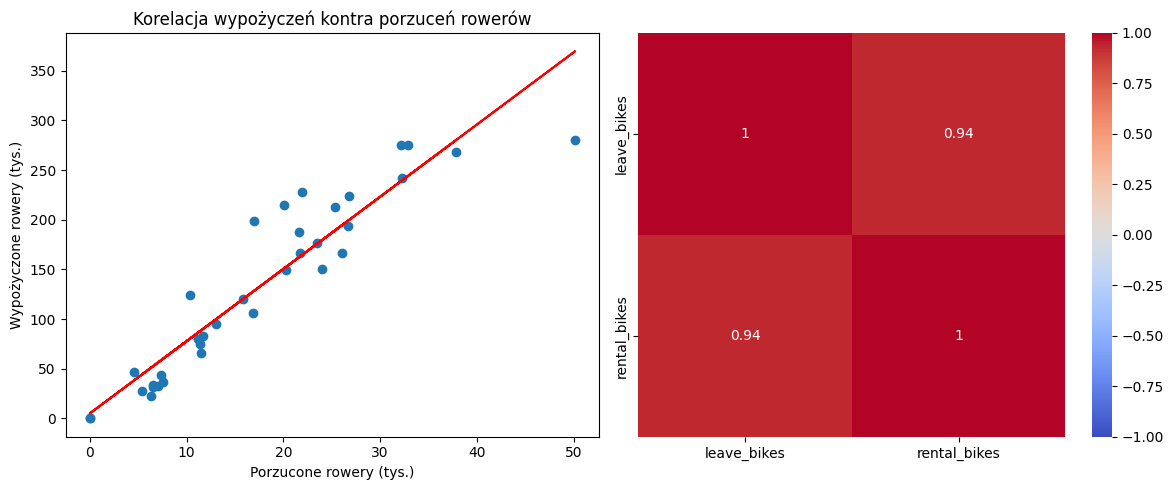

In [19]:
def calculate_regresion_line(x, y):
    x_m = x.mean()
    y_m  = y.mean()
    SXX = sum((x - x_m)**2)
    SXY = sum((x - x_m)*(y - y_m))
    b_1 = SXY/SXX
    b_0 = y_m - b_1 * x_m
    return b_0 + b_1 * x


y_pred  = calculate_regresion_line(bike_chart.loc[:,'leave_bikes'], bike_chart.loc[:,'rental_bikes'])

from matplotlib import pyplot as plt
import seaborn as sns
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.scatter(x=bike_chart['leave_bikes'], y=bike_chart['rental_bikes'])
plt.plot(bike_chart['leave_bikes'], y_pred, color='red')

plt.title('Korelacja wypożyczeń kontra porzuceń rowerów')
plt.xlabel('Porzucone rowery (tys.)')
plt.ylabel('Wypożyczone rowery (tys.)')

plt.subplot(1,2,2)
sns.heatmap(bike_chart.loc[:,['leave_bikes', 'rental_bikes']].corr(), 
            cmap='coolwarm', annot=True, vmin=-1, vmax=1)

plt.tight_layout()
plt.show()

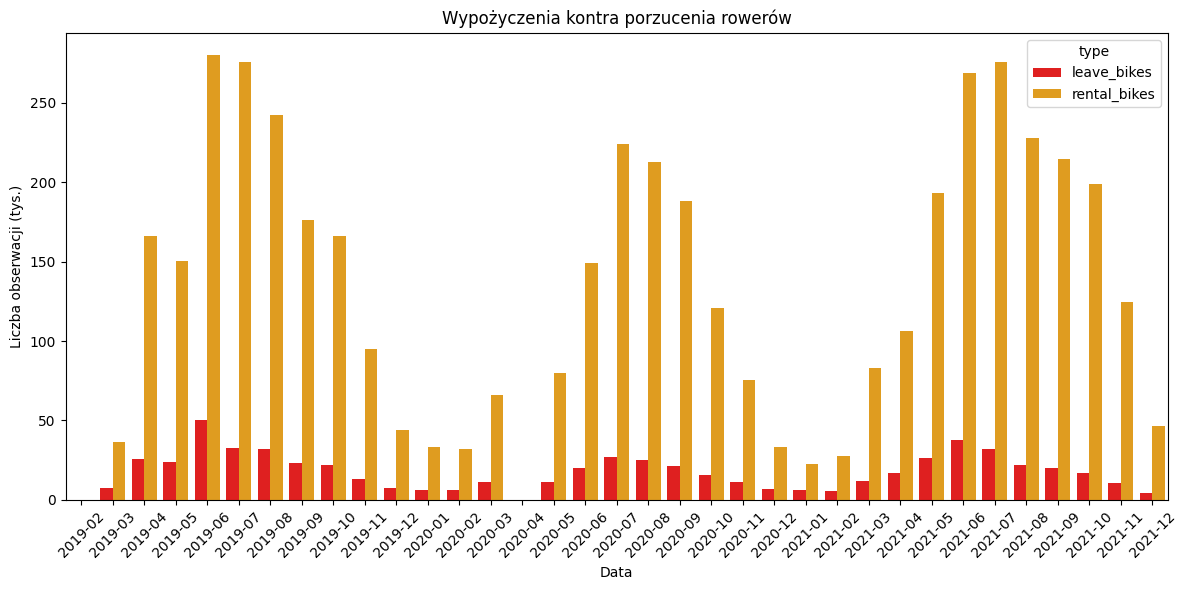

In [20]:
bike_melted = pd.melt(bike_chart, id_vars=['date'], value_vars=['leave_bikes', 'rental_bikes'], value_name='bikes', var_name='type')

plt.figure(figsize=(12,6))
sns.barplot(data=bike_melted, x='date', y='bikes', hue='type', palette=['red', 'orange'])
plt.xticks(rotation=45)
plt.title('Wypożyczenia kontra porzucenia rowerów')
plt.ylabel('Liczba obserwacji (tys.)')
plt.xlabel('Data')
plt.tight_layout()
plt.show()

Jak kształtują się wypożyczenia dla któych stacja początkowa i końcowa jest taka sama?

Czas wypożyczeń dla połowy takich obserwacji wynosił mniej niż 2 minuty, za to dla 90 percentyla wynosił ponad 50 minut.

Tak jak z poprzednimi rekordami, tutaj również porzucimy te zapisy. Nie wnoszą one nic do analizy, a wręcz mogą ją utrudnić.

In [21]:
bike_same_station = bike_dataset2[(bike_dataset2.iloc[:,4] == bike_dataset2.iloc[:,5])]
bike_same_station.describe()

,uid,bike_number,start_time,end_time,rental_time
count,7.705410e+05,770541.000000,770541,770541,770541.000000
mean,9.819012e+07,359575.067007,2020-06-08 05:40:32.572560640,2020-06-08 06:35:28.142853120,54.926178
min,6.539034e+07,27555.000000,2019-03-11 21:29:35,2019-03-11 22:03:22,0.020000
25%,7.985027e+07,57517.000000,2019-07-27 09:23:54,2019-07-27 10:59:19,0.680000
50%,9.849390e+07,650025.000000,2020-06-27 18:24:37,2020-06-27 19:10:08,1.980000
75%,1.158729e+08,650680.000000,2021-05-10 20:17:30,2021-05-10 20:56:45,9.580000
max,1.353896e+08,852853.000000,2021-12-31 23:50:29,2021-12-31 23:55:37,246975.380000
std,1.992667e+07,296551.811297,NaN,NaN,1384.244010


In [22]:
bike_same_station['rental_time'].quantile([q*0.1 for q in range(0,11,1)])

0.0         0.02
0.1         0.38
0.2         0.58
0.3         0.82
0.4         1.22
0.5         1.98
0.6         4.37
0.7         7.07
0.8        15.40
0.9        51.90
1.0    246975.38
Name: rental_time, dtype: float64

Po wykonaniu wymienionych operacji, zbiór pomniejsza się do liczby 3 864 904 rekordów.

In [23]:
bike_dataset2 = bike_dataset2[~(bike_dataset2.iloc[:,4] == bike_dataset2.iloc[:,5])]

In [24]:
bike_dataset2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3864904 entries, 893 to 5257353
Data columns (total 8 columns):
 #   Column        Dtype         
---  ------        -----         
 0   uid           int64         
 1   bike_number   int64         
 2   start_time    datetime64[ns]
 3   end_time      datetime64[ns]
 4   rental_place  object        
 5   return_place  object        
 6   date          object        
 7   rental_time   float64       
dtypes: datetime64[ns](2), float64(1), int64(2), object(3)
memory usage: 265.4+ MB


#### Pozyskiwanie lokalizacji geograficznej stacji rowerowych
Przystąpijmy do wykorzystania biblioteki geopy, która umożliwa połączenie się z api map. Posiłkujemy się bezpłatnym rozwiązaniem serwisu: [openstreetmap.org](https://www.openstreetmap.org/).

❗❗❗ZNORMALIZOWAC ZAPIS NAZW STACJI ROWEROWYCH (MALE LITERY) ❗❗❗

TUTAJ TAKŻE USUWAMY PUSTE ZNAKI

USUNIĘCIE STACJI BEZ LOKALIZACJI WYMAGA PONOWNEGO WYKONANIA ZAPYTANIA [TRZEBA TO ZMIENIĆ]

In [338]:
geolocation['Station'] = geolocation['Station'].apply(lambda x: x.lower())
geolocation = geolocation.replace('\xa0', '', regex=True)
geolocation = geolocation.replace(' )', ')')
geolocation = geolocation.replace('( ', '(')
geolocation

,Station,Latitude,Longitude
0,plac dominikański (galeria dominikańska),51.108004,17.039528
1,"dworzec główny, południe",51.097108,17.036110
2,rynek,51.109782,17.030175
3,dworzec główny,51.099750,17.036228
4,nowowiejska / jedności narodowej,51.124879,17.045844
...,...,...,...
235,bielany wrocławskie kolejowa p&r,51.037950,16.976374
236,wysoka nastrojowa,51.052835,17.003956
237,mokronos górny pkp,51.078886,16.908149
238,smolec,51.087048,16.911286


In [15]:
def station_without_coordinate(data, stations):
    station = set()
    for p in list(pd.unique(data.iloc[:,4])):
        station.add(p) if p not in list(stations) else None
        
    for p in list(pd.unique(data.iloc[:,5])):
        station.add(p) if p not in list(stations) else None
        
    return station


from geopy.geocoders import Nominatim
def get_coordinate(stations):
    locations = []
    geolocator = Nominatim(user_agent='get_coordinate')
    
    for s in stations:
        location = geolocator.geocode(''.join([s, ', Wrocław']))
        if location:
            locations.append([s, location.latitude, location.longitude])
        else:
            locations.append([s, None, None])
            
    return locations

In [ ]:
stations = station_without_coordinate(bike_dataset2, geolocation.iloc[:,0])
geolocation2 = get_coordinate(stations)

Rozwiązanie to pozwoliło na uzyskanie informacji o współrzędnych dla 21 możliwych stacji z 81 lokalizacji. Umożliwiło to ocalenie 79 681 rekordów. Pozostałe lokacje spróbujemy wyszukać ręcznie.

In [340]:
geolocation3 = pd.DataFrame(geolocation2, columns=['Station', 'Latitude', 'Longitude']).dropna().reset_index(drop=True)
geolocation3

,Station,Latitude,Longitude
0,urząd miejski,51.110198,17.031380
1,os. przyjaźni,51.069226,16.996667
2,arena,51.094464,17.026666
3,plac orląt lwowskich,51.108375,17.019010
4,kurkowa / dubois,51.118190,17.028858
5,os. sobieskiego,51.157814,17.132482
6,kozia,51.160893,16.928062
7,polanka,51.135696,17.032776
8,targowisko,51.109436,17.009926
9,cmentarz komunalny,51.124799,16.884443


In [341]:
bike_dataset2[(bike_dataset2['rental_place'].isin(geolocation3['Station']) | bike_dataset2['return_place'].isin(geolocation3['Station']))].info()

<class 'pandas.core.frame.DataFrame'>
Index: 79681 entries, 1666 to 5257226
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   uid           79681 non-null  int64         
 1   bike_number   79681 non-null  int64         
 2   start_time    79681 non-null  datetime64[ns]
 3   end_time      79681 non-null  datetime64[ns]
 4   rental_place  79681 non-null  object        
 5   return_place  79681 non-null  object        
 6   date          79681 non-null  object        
 7   rental_time   79681 non-null  float64       
dtypes: datetime64[ns](2), float64(1), int64(2), object(3)
memory usage: 5.5+ MB


In [342]:
geolocation_empty = pd.DataFrame(geolocation2, columns=['Station', 'Latitude', 'Longitude'])
geolocation_empty = geolocation_empty[geolocation_empty.isna().any(axis=True)].reset_index(drop=True)
geolocation_empty

,Station,Latitude,Longitude
0,rogowska/sukielicka,NaN,NaN
1,piłsudskiego / karkonoska,NaN,NaN
2,wojska polskiego/reja,NaN,NaN
3,pruślin szkoła,NaN,NaN
4,centrum przesiadkowe,NaN,NaN
5,podmiejska/orlik,NaN,NaN
6,bułgarska / marcelińska,NaN,NaN
7,cmentarz tyniecki,NaN,NaN
8,złotoryjska / sejmowa,NaN,NaN
9,pl. inwalidów wojennych,NaN,NaN


Bezpłatne API nie umożliwia jednak uzyskania wszystkich lokalizaji, dlatego pozostałe wyszukamy ręcznie, ~~z racji niewielkiej liczby braków~~. Dla rozwiązania produkcyjnego można rozważyć wykorzystanie płatnych API, tj.: Google, Bing, gdzie każde zapytanie kosztuje i wymaga utworzenia konta w tychże portalach.

In [343]:
geolocation4 = pd.DataFrame([
    ['rogowska/sukielicka', 51.118023849950696, 16.946136121490035],
    ['park przyjaźni', 51.068382816381764, 17.003880022178908],
    ['centrum przesiadkowe', 51.112170007977674, 17.06046747842664],
    ['powstańców śląskich (arkady wrocławskie)', 51.09968957120143, 17.027864916439423],
    ['botaniczna (ogród botaniczny - mini zoo)', 51.11680582274427, 17.051826823109263],
    ['strachowskiego / parafialna', 51.057033155892675, 17.023216648638797],
    ['hala stulecia - konferencja', 51.10593155360963, 17.07585136228343],
    ['dworcowa (dworzec kolejowy)', 51.10063818678078, 17.0393971132838],
    ['radeckiego / marcinkowskiego (uniw. medyczny - cnim)', 51.11176773962782, 17.06780286006257],
    ['walońska (angel poland group)', 51.10394328533369, 17.051924448047874],
    ['mahle', 51.1119015164667, 17.026152106077536],
    ['główny rynek', 51.11077770145831, 17.03120510355657]
], columns=['Station', 'Latitude', 'Longitude'])

Nieudało się wyszukać wszystkich stacji na terenie Wrocławia. Niektóre nazyw lokacji sugerowały inne miasta, np. Poznań, Ostrów Wielkopolski, Kalisz, Legnica. Jako, że operatorem praktycznie wszystkich takich systemów jest Nextbike, to możliwe, że niektóre zapisy znalazły się nie w tym systemie w którym powinny.

Jednak dzieki temu zostawiliśmy kolejne 151 391 rekordy w zbiorze.

In [344]:
bike_dataset2[(bike_dataset2['rental_place'].isin(geolocation4['Station']) | bike_dataset2['return_place'].isin(geolocation4['Station']))].info()

<class 'pandas.core.frame.DataFrame'>
Index: 151391 entries, 983 to 5257343
Data columns (total 8 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   uid           151391 non-null  int64         
 1   bike_number   151391 non-null  int64         
 2   start_time    151391 non-null  datetime64[ns]
 3   end_time      151391 non-null  datetime64[ns]
 4   rental_place  151391 non-null  object        
 5   return_place  151391 non-null  object        
 6   date          151391 non-null  object        
 7   rental_time   151391 non-null  float64       
dtypes: datetime64[ns](2), float64(1), int64(2), object(3)
memory usage: 10.4+ MB


Połączmy wszystkie metody uzyskania współrzędnych geograficznych oraz zapiszmy, aby nie powtarzać ponownie tej długotrwałej procedury i w póżniejszym czasie mieć szybki dostęp do danych.

In [345]:
locations = pd.concat([geolocation, geolocation3, geolocation4], ignore_index=True)
locations

,Station,Latitude,Longitude
0,plac dominikański (galeria dominikańska),51.108004,17.039528
1,"dworzec główny, południe",51.097108,17.036110
2,rynek,51.109782,17.030175
3,dworzec główny,51.099750,17.036228
4,nowowiejska / jedności narodowej,51.124879,17.045844
...,...,...,...
268,dworcowa (dworzec kolejowy),51.100638,17.039397
269,radeckiego / marcinkowskiego (uniw. medyczny -...,51.111768,17.067803
270,walońska (angel poland group),51.103943,17.051924
271,mahle,51.111902,17.026152


In [346]:
locations.to_csv('locations.csv', index=False, encoding='utf-8-sig', sep=';')

Utwórzmy jeszcze jedną tabele zawierającą nazwy lokalizacji dla których nie byliśmy znaleźć współrzędnych geograficznych.

Okazuje się, że z całego zestawienia liczącego prawie 4 miliony rekordów po selekcji musimy usunąć tylko 153 krotki. Jak na nie znalezienie 49 stacji jest wspaniale.

In [347]:
geolocation_remove = pd.DataFrame(geolocation2, columns=['Station', 'Latitude', 'Longitude'])
geolocation_remove = geolocation_remove[~geolocation_remove['Station'].isin(locations['Station'])]

In [348]:
bike_dataset2[(bike_dataset2['rental_place'].isin(geolocation_remove['Station']) | bike_dataset2['return_place'].isin(geolocation_remove['Station']))].info()

<class 'pandas.core.frame.DataFrame'>
Index: 153 entries, 156616 to 4980661
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   uid           153 non-null    int64         
 1   bike_number   153 non-null    int64         
 2   start_time    153 non-null    datetime64[ns]
 3   end_time      153 non-null    datetime64[ns]
 4   rental_place  153 non-null    object        
 5   return_place  153 non-null    object        
 6   date          153 non-null    object        
 7   rental_time   153 non-null    float64       
dtypes: datetime64[ns](2), float64(1), int64(2), object(3)
memory usage: 10.8+ KB


#### Odrzucenie rekordów z nieustaloną lokalizacją
Podczas wstępnego przetwarzania i walidacji zbiorów napotkano 82 unikalnych lokalizacji, które nie występowały w ustalonych już miejscach. Podjęto się próby pozyskania brakujących współrzędnych dotyczących miejsca rozpoczęcia lub zakończenia przejazdu. Wysiłki obejmowały wykorzystanie biblioteki geopy oraz manualne wyszukiwanie przy pomocy Google Maps. Tym sposobem udało się uzyskać informację o 32 stacjach.

Niestety nie udało się lokalizacji pozostałych 49 stacji, jednak dotyczą one niespełna 153 rekordów, co stanowi zaledwie 0.004 % już wyselekcjonowanego zbioru. Usunięcie tych obserwacji nie wpłynie na dalszy przebie prac.

Wybieramy rekordy dla których stacja początkowa, bądz końcowa zostałą ustalona. Zapiszemy zmiane pod nową zmienną.

In [25]:
locations = pd.read_csv('locations.csv', sep=';')
bike_dataset3 = bike_dataset2[(bike_dataset2['rental_place'].isin(locations['Station']) & bike_dataset2['return_place'].isin(locations['Station']))]

Możemy wyświetlić także rekordy dla który lokalizacji pozostaje nieznana. Korzystając prawa de morgana możemy pokazać, że zaprzeczenie koniunkcji dwóch zdań jest równoważne alternatywie zaprzeczeń tych zdań.

| P | Q | PnQ | ~(PnQ) | ~P v ~Q
|:---:|:---:|:---:|:---:|:---:|
| 0 | 0 | 0 | 1 | 1 |
| 0 | 1 | 0 | 1 | 1 |
| 1 | 0 | 0 | 1 | 1 |
| 1 | 1 | 1 | 0 | 0 |

In [26]:
bike_dataset2[
    (~bike_dataset2['rental_place'].isin(locations['Station']) | 
     ~bike_dataset2['return_place'].isin(locations['Station']))
].equals(
    bike_dataset2[
        ~(bike_dataset2['rental_place'].isin(locations['Station']) & 
          bike_dataset2['return_place'].isin(locations['Station']))
    ])

True

#### Wyliczenia odległości pomiędzy stacjami oraz prędkości dla wypożyczeń
Idealnym rozwiązaniem byłoby wyznaczenie pokonanej trasy na podstawie zapisu GPS (co znacząco zwiększa złożoność zadania, a także nie dysponujemy takimi danychmi), próba wytyczenia ścieżki takiej jaką uzyskujemy z poziomu Google Maps jest opcją (jednak wysłanie paru tysięcy zapytań pochłonie znaczące koszty i nie przyniesie znaczącego wpływu na wyniki). Pozostaje nam wykorzystanie przybliżonego podejścia, obliczając odległość stacji pomiędzy sobą w lini prostej w sferycznej przestrzeni metrycznej.

W pierwszej kolejności utworzymy zestawienie ze wszystkimy nazwami stacji i ich współrzędnymi, aby obliczyć odległości pomiędzy każdą stacją do każdej. Następnie będziemy przypisaywać głównegu zbiorowi, obliczone dystanse. Podejście takie pozwoli uniknąć zbędnych obliczeń i przypieszy analizę.

Przygotowujemy funkcję, które obliczą odległość pomiędzy dwiema lokalizacjiami na podstawie szerokości i długości geograficznych. Dystans jest obliczany przy wykorzystaniu formuły:

$$distance = 2 \times R \times \arcsin(\sqrt(\sin(\frac{lat_b - lat_a}{2})^2 + \cos(lat_a) \times \cos(lat_b) + \sin(\frac{lon_b - lon_a}{2})^2))$$

,gdzie:
- R - jest średnim promieniem Ziemi wynoszącym: 6371 km
- lat_a, lat_b, lon_a, lon_b - szerokościami i długościami geograficznymi w mierze kątowej (radianach)

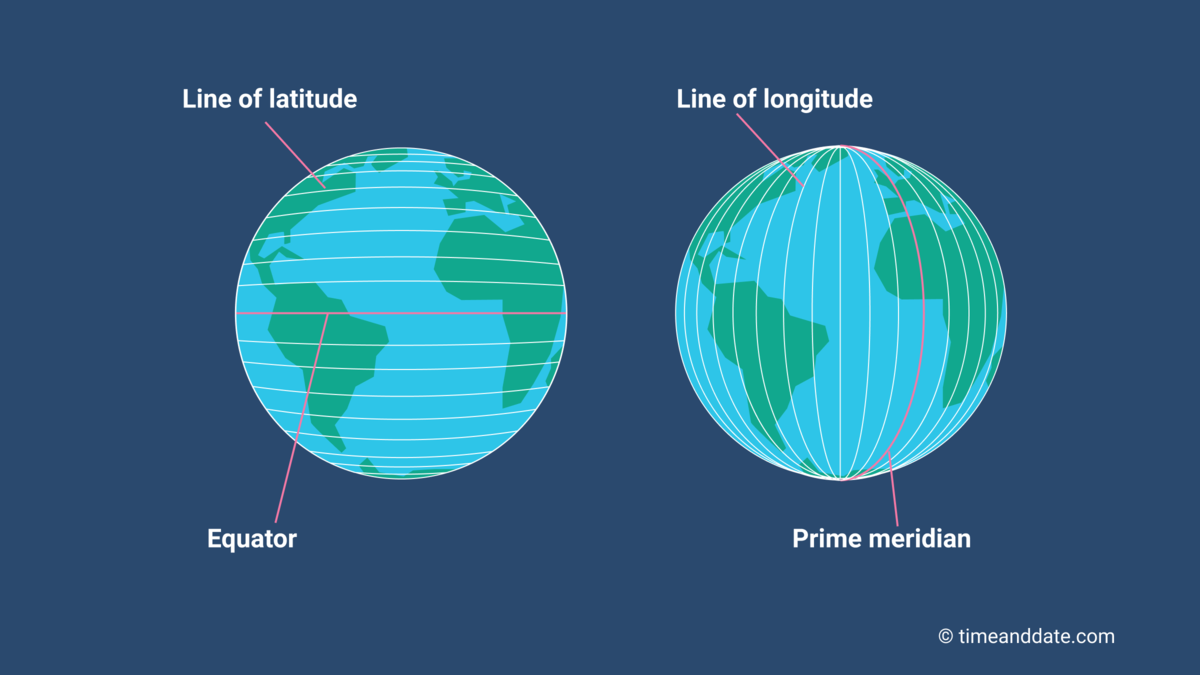

In [27]:
import math
from itertools import combinations


def haversine(lat1, lon1, lat2, lon2):
    lat1, lat2 = math.radians(lat1), math.radians(lat2)
    lon1, lon2 = math.radians(lon1), math.radians(lon2)
    
    diff_lat = lat2 - lat1
    diff_lon = lon2 - lon1
    
    a = math.sin(diff_lat/2)**2 + math.cos(lat1) * math.cos(lat2) * math.sin(diff_lon/2)**2
    
    earth_radius = 6371.0
    distance = 2 * earth_radius * math.asin(math.sqrt(a))
    
    return distance

Następna funkcja tworzy kombinację stacji z wykorzystaniem wcześniejszej definicji do obliczenia odległości. Korzystając z ciągu $a_n = \frac{n(n-1)}{2}$ dla $a_{273} = \frac{273\times 272}{2} = 37\space128$ możliwości.

In [28]:
def stations_combinations(stations):
    combinations_lst = []
    
    for first_station, second_station in combinations(stations.itertuples(), 2):
        combinations_lst.append({
            'first_station':    first_station[1],
            'second_station':   second_station[1],
            'distance':         haversine(first_station[2],
                                          first_station[3],
                                          second_station[2],
                                          second_station[3])
        })
    
    return pd.DataFrame(combinations_lst)

In [29]:
distances = stations_combinations(locations)
distances.sort_values('distance', ascending=False)

,first_station,second_station,distance
31245,strachocińska / wieśniacza,prochowicka / dolnobrzeska,19.979058
31253,strachocińska / wieśniacza,średzka / dolnobrzeska,19.754914
31275,strachocińska / wieśniacza,"wrocław leśnica, stacja kolejowa",19.734688
31724,prochowicka / dolnobrzeska,ziemniaczana/boiskowa,19.546758
18683,leśnica - pętla tramwajowa,strachocińska / wieśniacza,19.361239
...,...,...,...
6484,tyrmanda / mińska,trymanda / mińska,0.013920
29367,przyjaźni / karkonoska,park przyjaźni,0.008258
12810,sienkiewicza / wyszyńskiego,botaniczna (ogród botaniczny - mini zoo),0.002201
1873,rondo reagana,centrum przesiadkowe,0.002119


Przeprowadźmy teraz łączenie pozyskanych zestawów danych w jedną tablicę.

In [30]:
bike_dataset4 = bike_dataset3.merge(
    distances[['first_station', 'second_station', 'distance']],
    left_on=['rental_place', 'return_place'],
    right_on=['first_station', 'second_station'],
    how='left'
    )

bike_dataset4 = bike_dataset4.merge(
    distances[['second_station', 'first_station', 'distance']],
    left_on=['rental_place', 'return_place'],
    right_on=['second_station', 'first_station'],
    how='left')

bike_dataset4['distance'] = bike_dataset4[['distance_x', 'distance_y']].bfill(axis=1).iloc[:,0]

bike_dataset4.drop(columns=['first_station_x', 'second_station_x', 'distance_x', 
                     'second_station_y', 'first_station_y', 'distance_y'],
            inplace=True, axis=True)

Sprawdźmy czy występują jakiekolwiek braki w utworzonej tabeli.

In [31]:
bike_dataset4[bike_dataset4.iloc[:,-1].isnull()]

,uid,bike_number,start_time,end_time,rental_place,return_place,date,rental_time,distance


Obliczmy czasy przejazdu ze stacji początkowej do stacji końcowej dla każdego rekordu, korzystając ze wzoru: $$v = \frac{s}{t}$$

In [32]:
bike_dataset4['speed'] = bike_dataset4['distance']/(bike_dataset4['rental_time']/60)

Należy dokonać kolejnej selekcji rekordów, wydaje się być nieprawidopodobnym uzyskanie prędkości ponad 50 km/h dla 965 rekordów na rowerze w terenie zabudownym, a tym bardziej prędkości ponad dźwiękowych. $(\ge 1225km/h)$

In [33]:
bike_dataset4[bike_dataset4['speed']>50].info()

<class 'pandas.core.frame.DataFrame'>
Index: 965 entries, 50 to 3863935
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   uid           965 non-null    int64         
 1   bike_number   965 non-null    int64         
 2   start_time    965 non-null    datetime64[ns]
 3   end_time      965 non-null    datetime64[ns]
 4   rental_place  965 non-null    object        
 5   return_place  965 non-null    object        
 6   date          965 non-null    object        
 7   rental_time   965 non-null    float64       
 8   distance      965 non-null    float64       
 9   speed         965 non-null    float64       
dtypes: datetime64[ns](2), float64(3), int64(2), object(3)
memory usage: 82.9+ KB


Dokonajmy selekcji obserwacji uwzględniając przepisy lokalne dotyczące prędkości na terenie zabudowym, ~~a także czasu wypożyczenia dla trzykrotności rozstępu między kwartylowego, aby wyeliminować obserwacje ekstremalnie odstające.~~

Długi czas wypożyczenia może być awariami, problemami. Należy to sprawdzić jakie są to rekordy. Żaden użytkowanik nie chcę wynajmować rowerów ponad pewien określony czas gdyż koszty rosną gwałtownie. Pierwsze 20 minut jest darmowe, nie licząc opłaty aktywacyjnej.

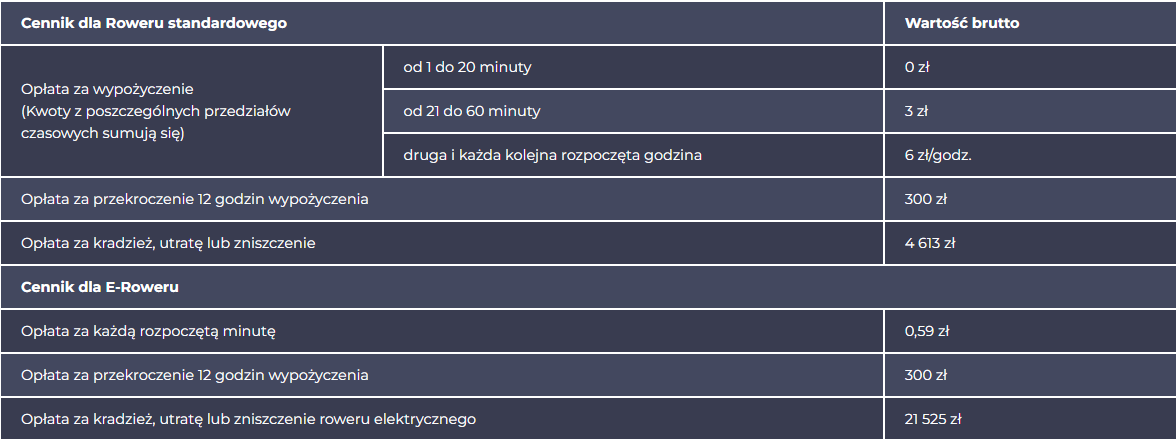

Uznajmy, że wypożyczenia powyżej trzech godzin są błędne. Usuwamy 20409 rekordów, stosując ograniczenie o wartości odstające możemy wyeliminować przez pomyłkę lokalne zjawiska. Arbitraline wybierzemy granice...

In [34]:
bike_dataset4[bike_dataset4['rental_time']>3*60].info()

<class 'pandas.core.frame.DataFrame'>
Index: 20409 entries, 187 to 3864124
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   uid           20409 non-null  int64         
 1   bike_number   20409 non-null  int64         
 2   start_time    20409 non-null  datetime64[ns]
 3   end_time      20409 non-null  datetime64[ns]
 4   rental_place  20409 non-null  object        
 5   return_place  20409 non-null  object        
 6   date          20409 non-null  object        
 7   rental_time   20409 non-null  float64       
 8   distance      20409 non-null  float64       
 9   speed         20409 non-null  float64       
dtypes: datetime64[ns](2), float64(3), int64(2), object(3)
memory usage: 1.7+ MB


Stworzymy również histogram obrazujący jak wygląda liczba wypożyczeń w zależności od jego czasu

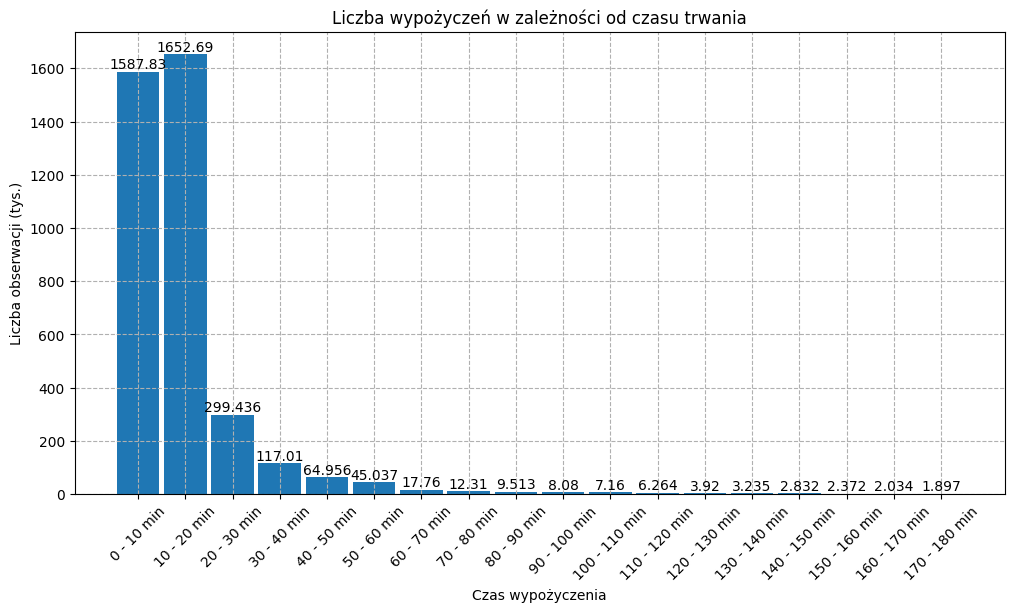

In [142]:
bins = list(range(0, 180+1, 10))
bike_dataset4['time_bin'] = pd.cut(
    bike_dataset4['rental_time'],
    bins=bins,
    labels=[f'{b} - {b+10} min' for b in bins[:-1]]
)

duration_counts = (bike_dataset4['time_bin'].value_counts()/1000).sort_index()

fig, ax = plt.subplots(figsize=(12, 6))
bar_cont = ax.bar(duration_counts.index, duration_counts.values, 0.9)
ax.bar_label(bar_cont)

plt.xticks(rotation=45)
plt.title('Liczba wypożyczeń w zależności od czasu trwania')
plt.ylabel('Liczba obserwacji (tys.)')
plt.xlabel('Czas wypożyczenia')
plt.grid(ls='--')
plt.show()

Dokonujemy selekcji rekordów

In [36]:
bike_dataset5 = bike_dataset4[bike_dataset4['speed'] <= 50.0]
bike_dataset5 = bike_dataset5[bike_dataset5['rental_time']<=3*60]
bike_dataset5.describe()

,uid,bike_number,start_time,end_time,rental_time,distance,speed
count,3.843377e+06,3.843377e+06,3843377,3843377,3.843377e+06,3.843377e+06,3.843377e+06
mean,1.028793e+08,3.972114e+05,2020-08-19 00:27:17.480294144,2020-08-19 00:42:23.053424640,1.509289e+01,1.858379e+00,8.779326e+00
min,6.553372e+07,3.951600e+04,2019-03-15 10:37:14,2019-03-15 10:42:18,1.200000e-01,1.343648e-03,1.671416e-03
25%,8.495496e+07,5.759800e+04,2019-09-12 13:42:25,2019-09-12 13:56:49,7.530000e+00,9.977361e-01,6.898266e+00
50%,1.040761e+08,6.501680e+05,2020-08-25 18:24:36,2020-08-25 18:42:24,1.143000e+01,1.566341e+00,8.875301e+00
75%,1.206853e+08,6.507440e+05,2021-06-29 20:49:54,2021-06-29 21:07:20,1.663000e+01,2.355512e+00,1.081844e+01
max,1.353895e+08,6.517130e+05,2021-12-31 23:44:19,2021-12-31 23:58:36,1.800000e+02,1.817847e+01,4.998471e+01
std,1.992651e+07,2.934403e+05,NaN,NaN,1.545399e+01,1.244734e+00,3.195494e+00


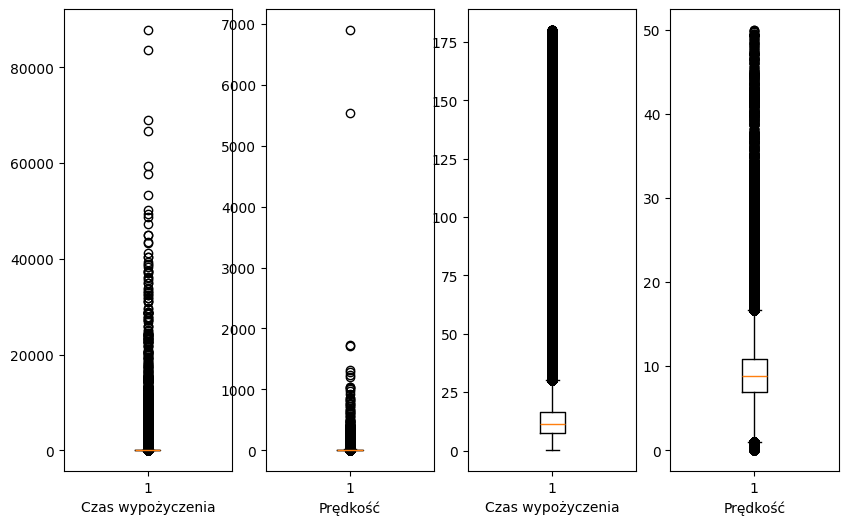

In [57]:
plt.figure(figsize=(10,6))
plt.subplot(1,4,1)
plt.boxplot(bike_dataset4['rental_time'])
plt.xlabel('Czas wypożyczenia')

plt.subplot(1,4,2)
plt.boxplot(bike_dataset4['speed'])
plt.xlabel('Prędkość')

plt.subplot(1,4,3)
plt.boxplot(bike_dataset5['rental_time'])
plt.xlabel('Czas wypożyczenia')

plt.subplot(1,4,4)
plt.boxplot(bike_dataset5['speed'])
plt.xlabel('Prędkość')

plt.show()

W rozkładzie prawdopodobieństwa dominuje prędkość 8.87 km/h. Rzeczywista tempo przemieszczania się użytkownika może być wyższe. Po pierwsze dokonaliśmy uproszczenia w postaci obliczenia odległośni między stacjami w lini prostej. Drugim czynnikiem jest nie uwzględnianie infrastruktury drogowej, tj. sygnalizacja, problematyczne ścieżki rowerowe o ile są to kończą się w niespodziewanych momentach i trzeba włączać się do ruchu drogowego.

Powołując się na mój przykład mogę powiedzieć, że praktycznie każdego dnia pokonuje z dworca do uczelni, a potem z powrotem 1.8 kilometra. Gdzie w lini prostej jest to już tylko 1.2 km. Jako że ta trasa zajmuje mi 7 minut. To uzyskujemy prędkość 15.42km/h, a w uproszczonym wariancie 10.28 km/h. Także uzyskujemy błąd względny na poziomi 33.(3)%.

Dodajmy do tego, że użytkownik może w dodatku poruszać się nieoptymalną trasą, czyli nie najkrótszą i nasz uproszczony model będzie miał jeszcze większe rozbieżności. A może nawet zatrzymał wypożyczenie, aby wejść do np. sklepu i nie martwić się szukaniem następnego roweru.

In [79]:
pd.DataFrame(bike_dataset5['speed'].describe()).T

,count,mean,std,min,25%,50%,75%,max
speed,3843377.0,8.779326,3.195494,0.001671,6.898266,8.875301,10.818441,49.984708


<Figure size 1000x600 with 0 Axes>

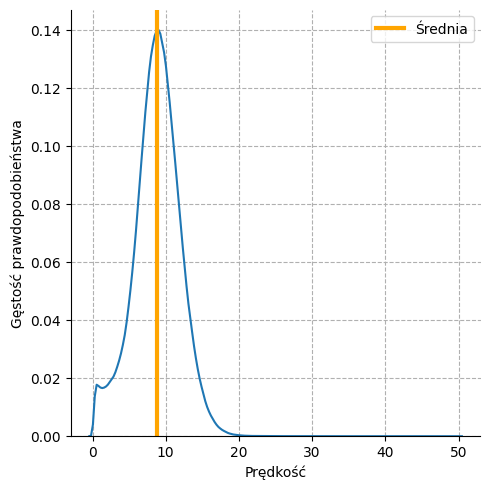

In [80]:
plt.figure(figsize=(10,6))
sns.displot(bike_dataset5['speed'], kind='kde')
plt.axvline(bike_dataset5['speed'].mean(), c='orange', lw=3, label='Średnia')
plt.ylabel('Gęstość prawdopodobieństwa')
plt.xlabel('Prędkość')
plt.legend()
plt.grid(ls='--')
plt.show()

### OpenData.meteo.uni.wroc.pl

In [436]:
import pandas as pd
pogoda = pd.read_excel('pogoda.xlsx')

In [437]:
pogoda.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24851 entries, 0 to 24850
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Data Godzina  24851 non-null  datetime64[ns]
 1   pressure      24848 non-null  float64       
 2   pm10          21196 non-null  float64       
 3   pm25          23386 non-null  float64       
 4   rain_01       24848 non-null  float64       
 5   t_2m          24848 non-null  float64       
 6   humidity      24848 non-null  float64       
 7   wind_a        24813 non-null  float64       
 8   wind_v        24813 non-null  float64       
dtypes: datetime64[ns](1), float64(8)
memory usage: 1.7 MB


In [438]:
pogoda[pogoda['pressure'].isna()]

,Data Godzina,pressure,pm10,pm25,rain_01,t_2m,humidity,wind_a,wind_v
6899,2019-12-13 11:00:00,NaN,13.0,NaN,NaN,NaN,NaN,89.6,156.0
24261,2021-12-07 10:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
24262,2021-12-07 11:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [439]:
pogoda.isna().sum()

Data Godzina       0
pressure           3
pm10            3655
pm25            1465
rain_01            3
t_2m               3
humidity           3
wind_a            38
wind_v            38
dtype: int64

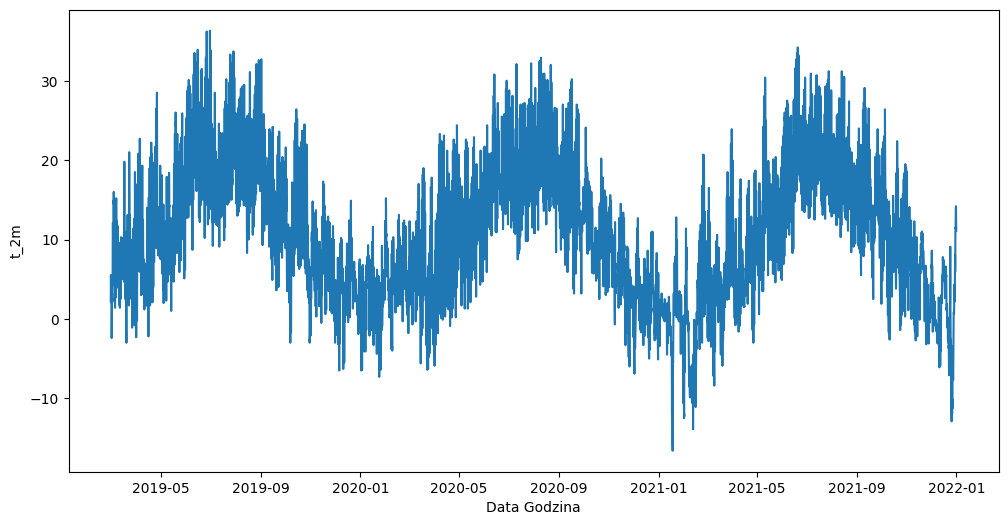

In [441]:
# pogoda.iloc[:,2:6].plot()

import seaborn as sns
from matplotlib import pyplot as plt
plt.figure(figsize=(12,6))
sns.lineplot(data=pogoda, x='Data Godzina', y='t_2m')
# sns.lineplot(data=pogoda, x='Data Godzina', y='rain_01')
# sns.lineplot(data=pogoda, x='Data Godzina', y='humidity')
# sns.lineplot(data=pogoda, x='Data Godzina', y='wind_a')
# sns.lineplot(data=pogoda, x='Data Godzina', y='wind_v')
# sns.lineplot(data=pogoda, x='Data Godzina', y='pm25')
# sns.lineplot(data=pogoda, x='Data Godzina', y='pm10')
# plt.legend()
plt.show()

In [408]:
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

# Przygotowanie danych
pogoda2 = pogoda.dropna()
X = pogoda2[['pressure', 't_2m', 'humidity', 'rain_01', 'wind_a', 'wind_v']]  # Zmienna objaśniające
y = pogoda2['pm25']  # Zmienna docelowa (to samo możesz zrobić dla PM10)

# Podział na dane treningowe i testowe
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Trenowanie modelu
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Przewidywanie
y_pred = model.predict(X_test)

# Ocena modelu
mse = mean_squared_error(y_test, y_pred)
print(f'MSE: {mse}')

MSE: 52.568185939865835


### INNE
- złączenie odelełości miedzy stacjami z prędkością i odrzucaniem predkosci dzwiekowej✅
- data i godzina, dzien tygodnia a moze w analizie✅
- uzupełnienie danch w pogodzie i połączenie z wypożyczenmiami
- zbadanie korelacji

---
- podział stacji ze wzgledu na predkosc, odleglosc, czas, (większość stacji ma takie same parametry)
- mapy ciepła z historią
- grafy✅
- najpopularniejsze stacje, trasy✅

---
dodatkowa zmienna dla pandemi

## Analiza wykorzystania systemu rowerów miejskich

#### Dzień tygodnia i godzina wypożyczeń
Możemy dostrzec, że najwięcej wynajmów dokonywanych jest w porannych godzinach 7-8 oraz wieczorem 16-17. Po sporządzeniu dokładniejszych wykresów można spostrzec, że takie zachowanie obejmuje tylko tydzień roboczy, gdzie mamy dwa szczyty. W dni wolne nie ma porannego szczytu, a jest jeden powolny narastający ruch, który osiąga swój kres o godzinach 14-18. Zgodnie z logiką większość wypożyczeń odbywa się za dnia, większość śpi, jest chłodniej, a także z racji zmroku poruszanie się (powiedzmy to słabo oświetlonym rowerem) jest niebezpieczne.

In [188]:
bike_dataset5['day_of_week'] = bike_dataset5['start_time'].dt.day_name()
bike_dataset5['hour'] = bike_dataset5['start_time'].dt.hour
bike_dataset5['month'] = bike_dataset5['start_time'].dt.month

Średnie liczby wypożyczeń w zależności od godziny osobno dla dni oraz miesięcy mają taki sam kształt. Mimo to warto mieć obydwa wykresy dla tych przedziałów czasowych.

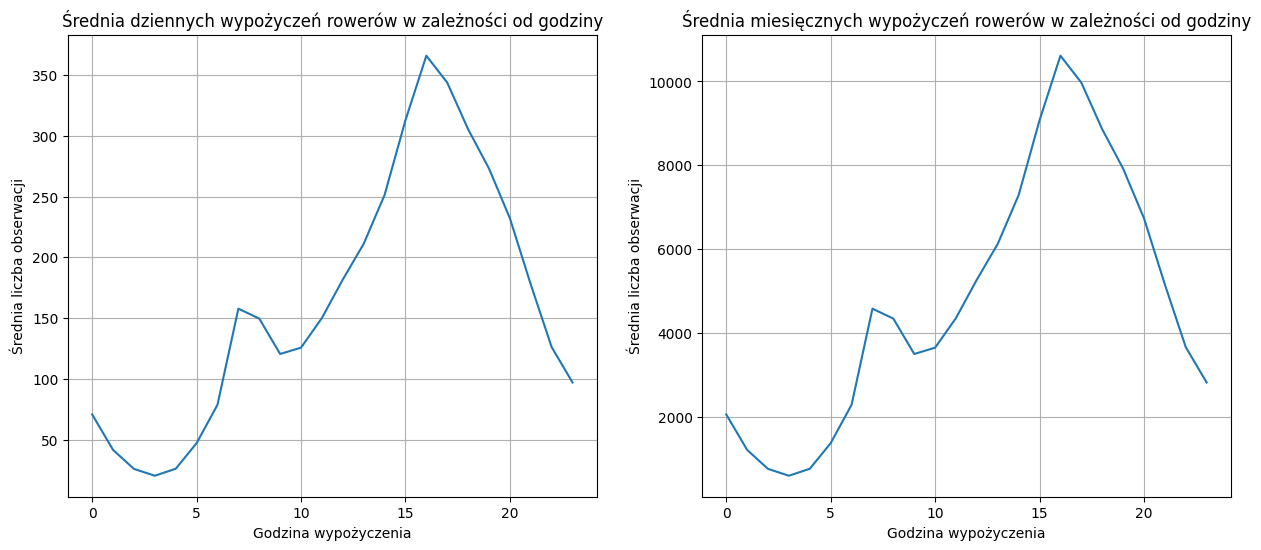

In [189]:
plt.figure(figsize=(15,6))
plt.subplot(1,2,1)
plt.plot(bike_dataset5.groupby('hour').size() / bike_dataset5['start_time'].dt.date.nunique())
plt.title('Średnia dziennych wypożyczeń rowerów w zależności od godziny')
plt.ylabel('Średnia liczba obserwacji')
plt.xlabel('Godzina wypożyczenia')
plt.grid(True, linestyle='-')
# plt.show()

plt.subplot(1,2,2)
# plt.subplots(figsize=(10,6))
plt.plot(bike_dataset5.groupby('hour').size() / bike_dataset5['date'].nunique())
plt.title('Średnia miesięcznych wypożyczeń rowerów w zależności od godziny')
plt.ylabel('Średnia liczba obserwacji')
plt.xlabel('Godzina wypożyczenia')
plt.grid(True, linestyle='-')
plt.show()

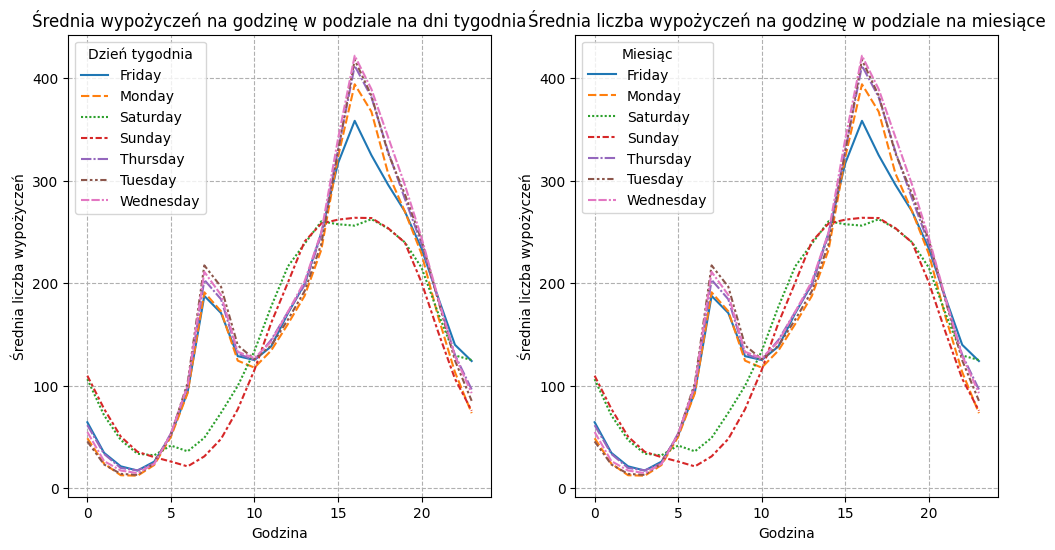

In [238]:
dayly_mean_rentals = bike_dataset5.groupby(['day_of_week', 'hour']).size() / bike_dataset5['start_time'].dt.to_period('W').nunique()
dayly_mean_rentals = dayly_mean_rentals.unstack('day_of_week')

plt.figure(figsize=(12, 6))
plt.subplot(1,2,1)
sns.lineplot(dayly_mean_rentals)
plt.xlabel('Godzina')
plt.ylabel('Średnia liczba wypożyczeń')
plt.title('Średnia wypożyczeń na godzinę w podziale na dni tygodnia')
plt.legend(title='Dzień tygodnia', loc='upper left')
plt.grid(linestyle='--')


monthly_mean_rentals = bike_dataset5.groupby(['month', 'hour']).size() / bike_dataset5['start_time'].dt.to_period('M').nunique()
monthly_mean_rentals = monthly_mean_rentals.unstack(level='month')

plt.subplot(1,2,2)
sns.lineplot(dayly_mean_rentals)
plt.xlabel('Godzina')
plt.ylabel('Średnia liczba wypożyczeń')
plt.title('Średnia liczba wypożyczeń na godzinę w podziale na miesiące')
plt.legend(title='Miesiąc', loc='upper left')
plt.grid(linestyle='--')
plt.show()

Przygotowanie toższamego wykresu jako mapa ciepła nie daje lepszego zrozumienia zachodzących zmian, a wręcz utrudnia.

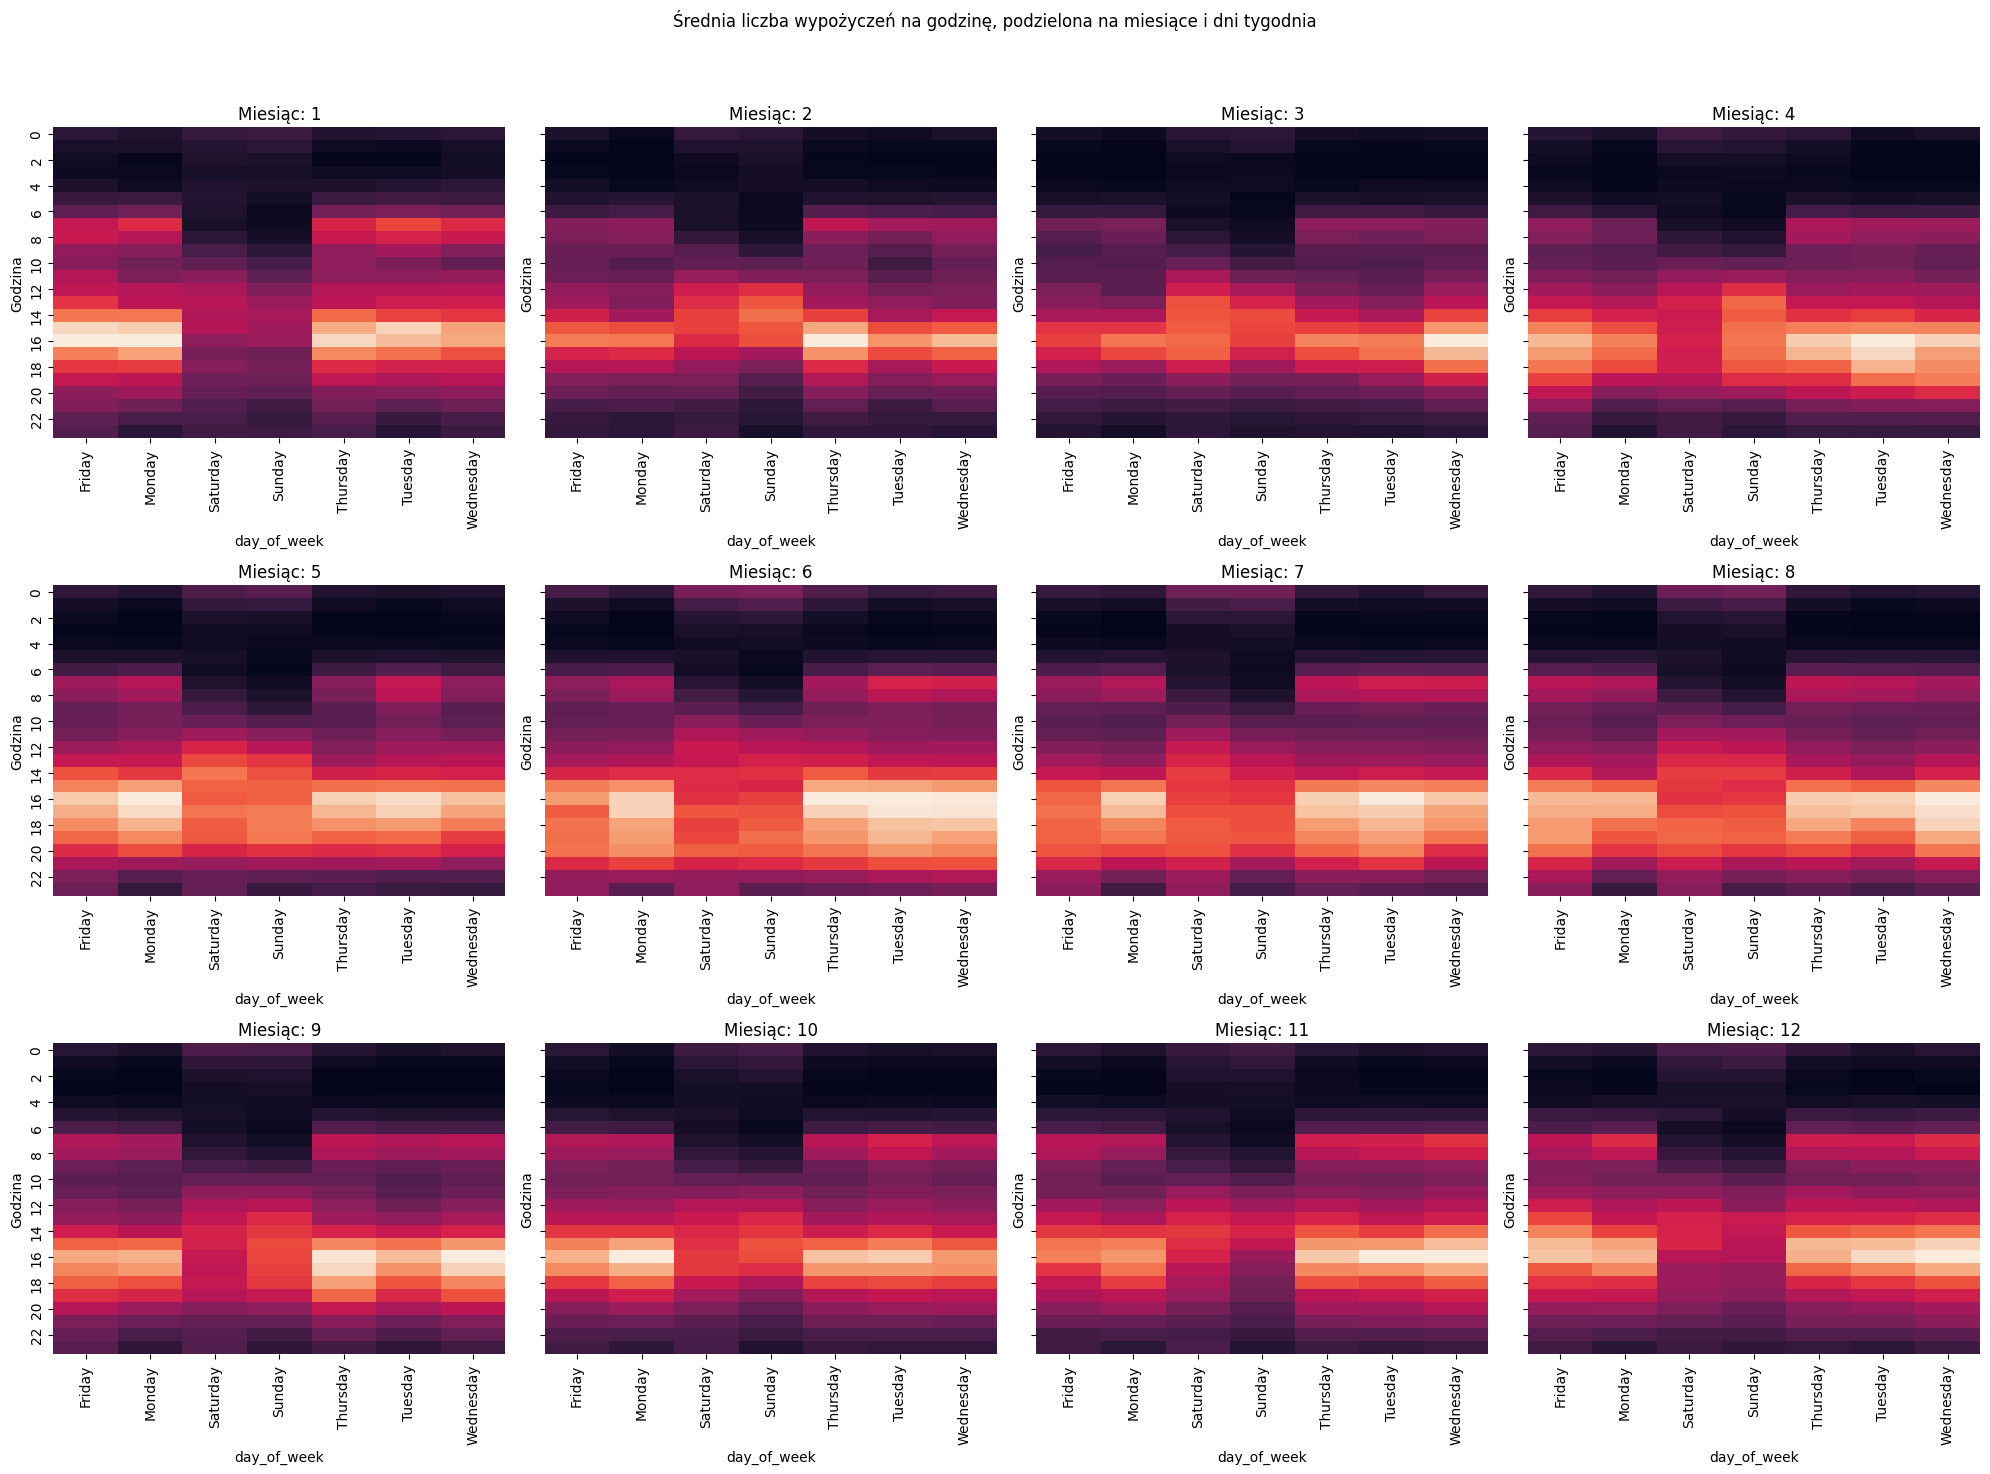

In [ ]:
grouped_data = bike_dataset5.groupby(['month', 'day_of_week', 'hour']).size()
unique_days_per_month = bike_dataset5.groupby(['month', 'day_of_week']).start_time.apply(lambda x: x.dt.date.nunique())
avg_rentals = (grouped_data / unique_days_per_month).unstack(level=['month', 'day_of_week'])
avg_rentals

fig, axes = plt.subplots(3, 4, figsize=(20, 15), sharey=True)
fig.suptitle('Średnia liczba wypożyczeń na godzinę, podzielona na miesiące i dni tygodnia')

# Iterowanie przez miesiące
for month in range(1, 13):
    ax = axes[(month-1) // 4, (month-1) % 4]
    sns.heatmap(avg_rentals[month], ax=ax, cbar=False)
    ax.set_title(f'Miesiąc: {month}')
    ax.set_ylabel('Godzina')

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

#### Wykorzystanie konkretnych rowerów
Utworzymy zestawienie rowerów, aby sprawdzić które rowery są najczęściej wypożyczene, a z tego względu wymagają częstszego serwisowania, aby zapewnić użytkowniką najwyższy standard obsługi. Nikt nie chcę wziąć roweru, który jest uszkodzony.

In [96]:
bike_summary = bike_dataset5.groupby('bike_number').agg({
    'distance':     'sum',
    'rental_time':  'sum'
}).reset_index()
bike_summary['rental_count'] = bike_dataset5.groupby('bike_number').size().values

bike_summary

,bike_number,distance,rental_time,rental_count
0,39516,0.742109,30.37,1
1,39546,3.030663,19.00,1
2,39547,0.925973,24.50,1
3,39577,4.274145,68.15,1
4,39579,3.497785,4.77,1
...,...,...,...,...
2772,651708,152.276349,1080.42,82
2773,651709,218.686260,1650.95,114
2774,651710,324.503016,2550.49,168
2775,651711,336.686791,2294.64,153


In [115]:
bike_summary.iloc[:,1:4].describe().T

,count,mean,std,min,25%,50%,75%,max
distance,2777.0,2572.003156,1176.322866,0.002119,1891.089777,2911.896601,3474.220976,4683.134653
rental_time,2777.0,20888.604346,9556.405368,0.570000,15290.100000,23733.110000,28308.230000,37844.350000
rental_count,2777.0,1384.003241,634.064428,1.000000,1021.000000,1569.000000,1872.000000,2533.000000


<Axes: xlabel='rental_count'>

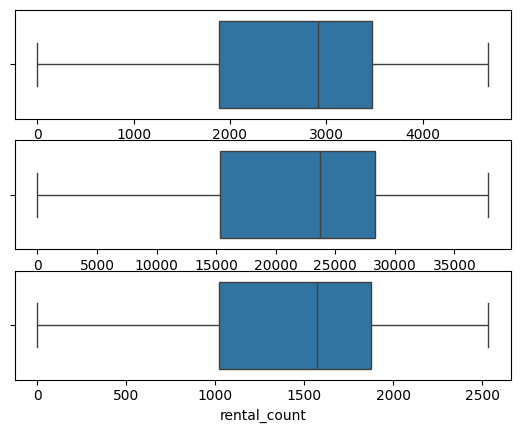

In [158]:
plt.subplot(3,1,1)
sns.boxplot(x=bike_summary['distance'])

plt.subplot(3,1,2)
sns.boxplot(x=bike_summary['rental_time'])

plt.subplot(3,1,3)
sns.boxplot(x=bike_summary['rental_count'])

~~Histogramy ukazują średnią i medianę o zbiżonych wartościach, co wskazuje na rozkład normalny danych. Najwięcej obserwacji występuje w pobliżu średniej / mediany, a mniej wartości występuje po obu stronach.~~

~~Występuję jednak zwiększenie liczby obserwacji o niskich wartościach. Sugeruje to, że te rowery były niezwykle rzadko wypożyczane. W takim razie gdzie stały przez większość czasu?~~

Histogramy prezentują rozkład lewoskośny (średnia < mediany < dominanta). Oznacza to, że co najmniej połowa użytkowaników pokonuje odległości większe, jeździ dłużej, wypożycza więcej niż średnia. Najeży przy tym zwrócić uwagę na wysokie wskazania na krańcu lewego ogona.

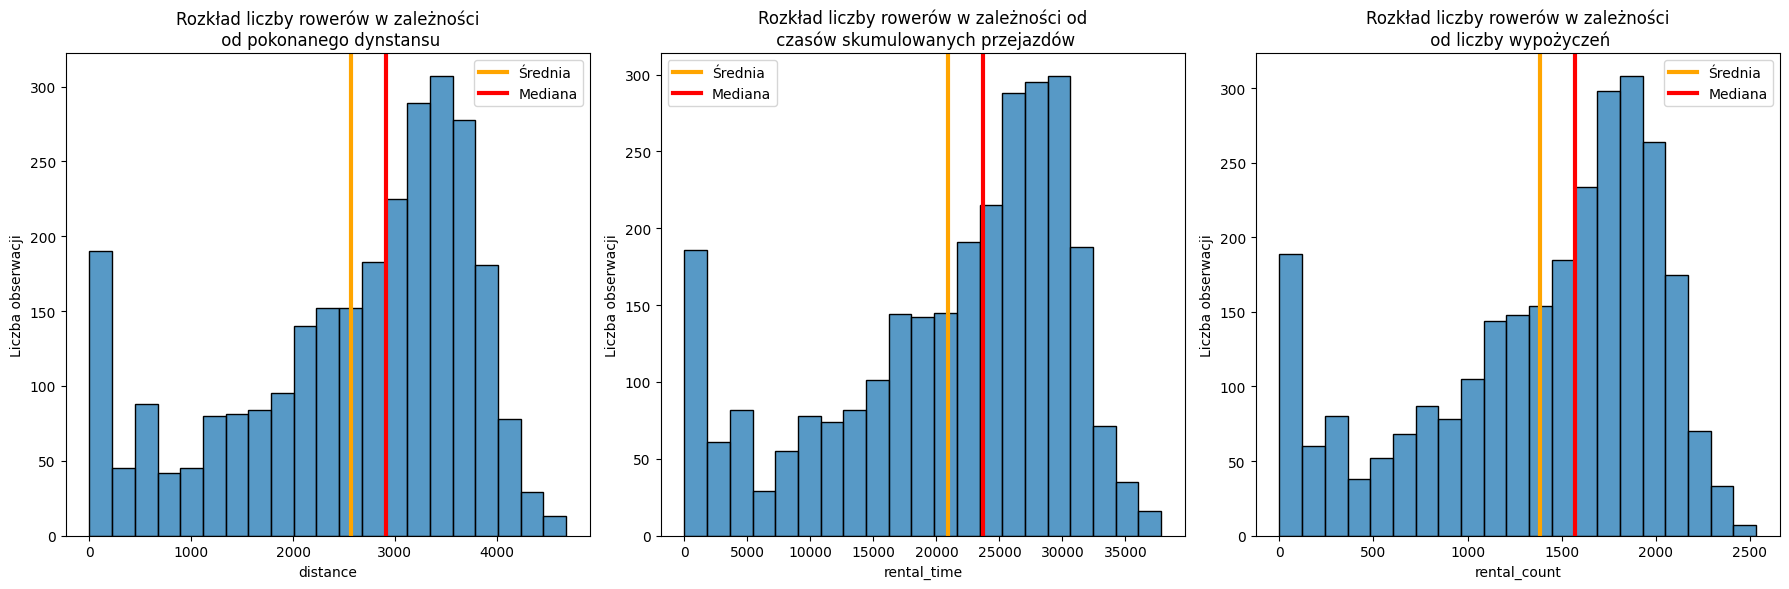

In [99]:
plt.figure(figsize=(18,6))
plt.subplot(1,3,1)
sns.histplot(data=bike_summary, x='distance').set(ylabel='Liczba obserwacji')
plt.axvline(bike_summary['distance'].mean(), c='orange', lw=3, label='Średnia')
plt.axvline(bike_summary['distance'].median(), c='red', lw=3, label='Mediana')
plt.title('Rozkład liczby rowerów w zależności\n od pokonanego dynstansu')
plt.legend()

plt.subplot(1,3,2)
sns.histplot(data=bike_summary, x='rental_time').set(ylabel='Liczba obserwacji')
plt.axvline(bike_summary['rental_time'].mean(), c='orange', lw=3, label='Średnia')
plt.axvline(bike_summary['rental_time'].median(), c='red', lw=3, label='Mediana')
plt.title('Rozkład liczby rowerów w zależności od\n czasów skumulowanych przejazdów')
plt.legend()

plt.subplot(1,3,3)
sns.histplot(data=bike_summary, x='rental_count').set(ylabel='Liczba obserwacji')
plt.axvline(bike_summary['rental_count'].mean(), c='orange', lw=3, label='Średnia')
plt.axvline(bike_summary['rental_count'].median(), c='red', lw=3, label='Mediana')
plt.title('Rozkład liczby rowerów w zależności\n od liczby wypożyczeń')
plt.legend()

plt.tight_layout()
plt.show()

Stworzenie listy rowerów, które pokonały najwięszy dystans i poruszały się najdłużej może wpłynąć na usprawnienie systemu. Można zlecić dodatkowe przeglądy najczęściej eksploatowanych sztuk, aby zapobieć awarią środka transportu.

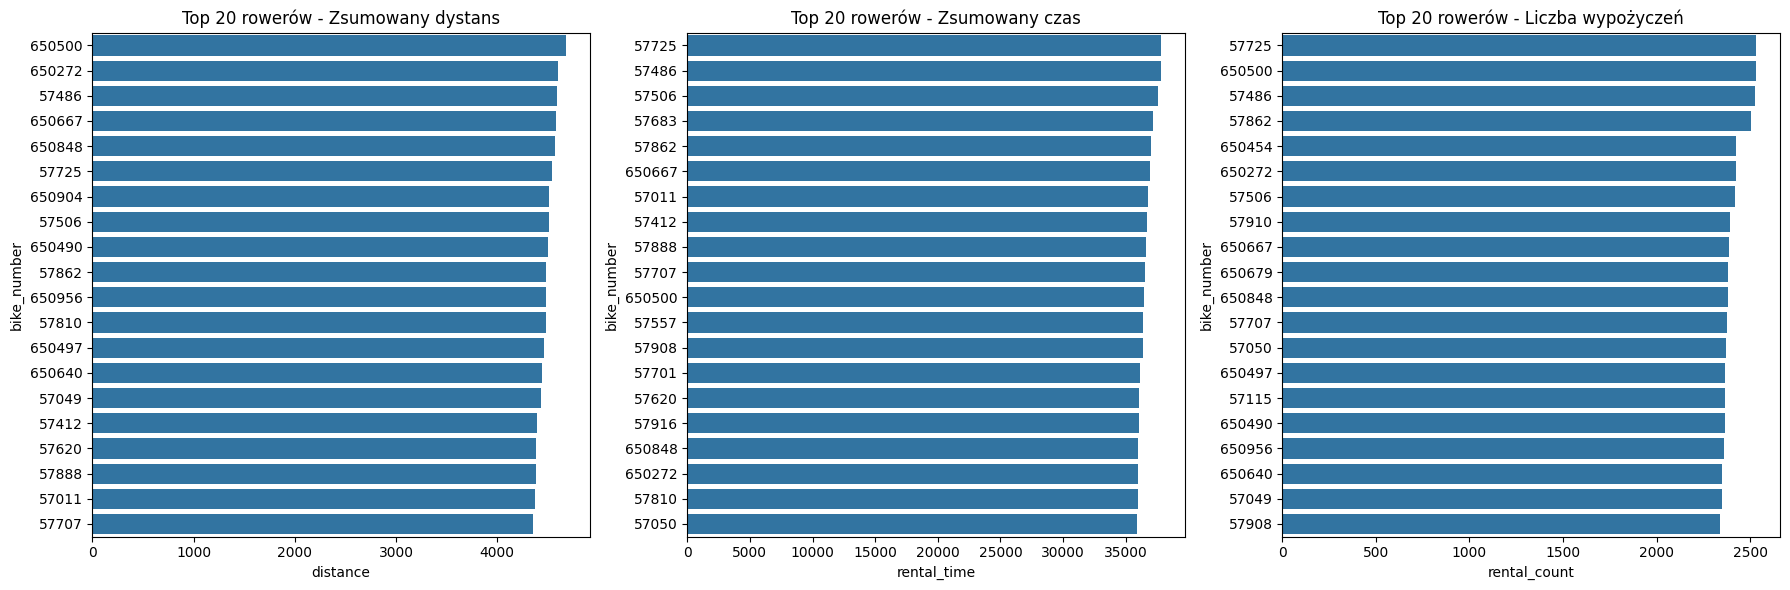

In [104]:
top_dystans = bike_summary.nlargest(20, 'distance')
top_czas = bike_summary.nlargest(20, 'rental_time')
top_wypozyczenia = bike_summary.nlargest(20, 'rental_count')


plt.figure(figsize=(18,6))

plt.subplot(1,3,1)
sns.barplot(x='distance', y='bike_number',
            data=top_dystans, orient='h',
            order=top_dystans['bike_number'])
plt.title('Top 20 rowerów - Zsumowany dystans')

plt.subplot(1,3,2)
sns.barplot(x='rental_time', y='bike_number', 
            data=top_czas, orient='h',
            order=top_czas['bike_number'])
plt.title('Top 20 rowerów - Zsumowany czas')


plt.subplot(1,3,3)
sns.barplot(x='rental_count', y='bike_number',
            data=top_wypozyczenia, orient='h',
            order=top_wypozyczenia['bike_number'])
plt.title('Top 20 rowerów - Liczba wypożyczeń')

plt.tight_layout()
plt.show()

Najgorsze statystyki wypożyczeń mogą wskazywać na nieefektywne wykorzystanie systemu. Najlepszym wyjściem było by przeniesienie nieszcześliwych rowerów na inne stację. Może to także wskazywać na problem techniczny z danym pojazdem albo za dużą dostępność. (Nie mamy przecież detekcji sytuacji w których brakuje rowerów, wtedy użytkownik zmuszony jest przejść na następną stację.)

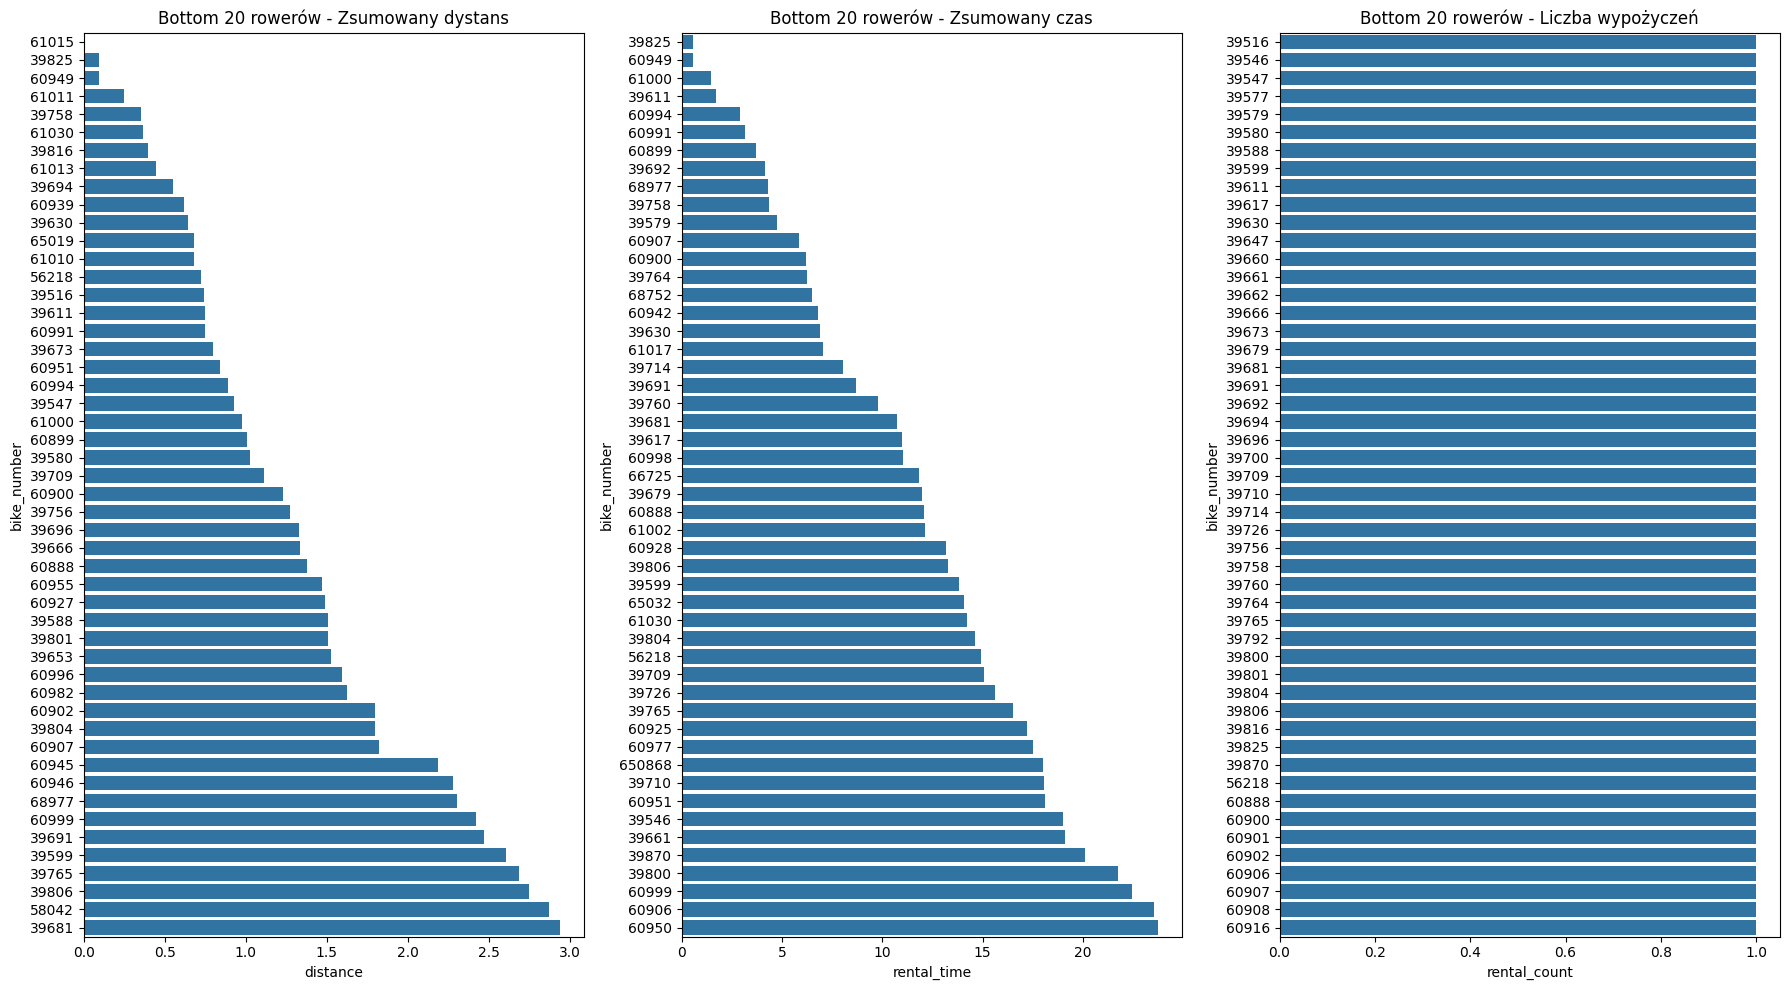

In [159]:
bottom_dystans = bike_summary.nsmallest(50, 'distance')
bottom_czas = bike_summary.nsmallest(50, 'rental_time')
bottom_wypozyczenia = bike_summary.nsmallest(50, 'rental_count')


plt.figure(figsize=(18,10))
plt.subplot(1,3,1)
sns.barplot(x='distance', y='bike_number',
            data=bottom_dystans, orient='h',
            order=bottom_dystans['bike_number'])
plt.title('Bottom 20 rowerów - Zsumowany dystans')

plt.subplot(1,3,2)
sns.barplot(x='rental_time', y='bike_number', 
            data=bottom_czas, orient='h',
            order=bottom_czas['bike_number'])
plt.title('Bottom 20 rowerów - Zsumowany czas')

plt.subplot(1,3,3)
sns.barplot(x='rental_count', y='bike_number',
            data=bottom_wypozyczenia, orient='h',
            order=bottom_wypozyczenia['bike_number'])
plt.title('Bottom 20 rowerów - Liczba wypożyczeń')

plt.tight_layout()
plt.show()

Korelacja pomiędzy liczbą wypożyczeń, czasem wypożyczenia, a pokonanym dystansem wydaję się oczywisty. Im więcej wypożyczeń tym i dłuższy czas oraz pokonana odległość.

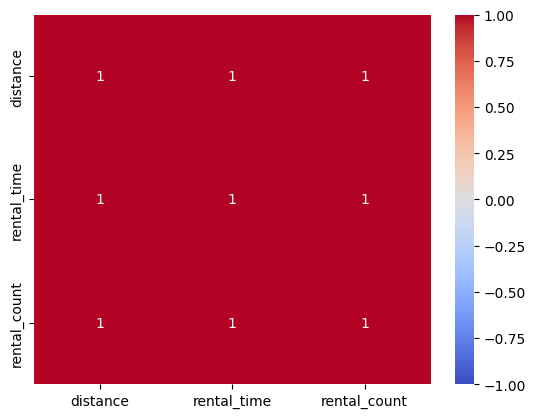

In [160]:
sns.heatmap(bike_summary.iloc[:,1:4].corr(), vmin=-1, vmax=1, annot=True, cmap='coolwarm')

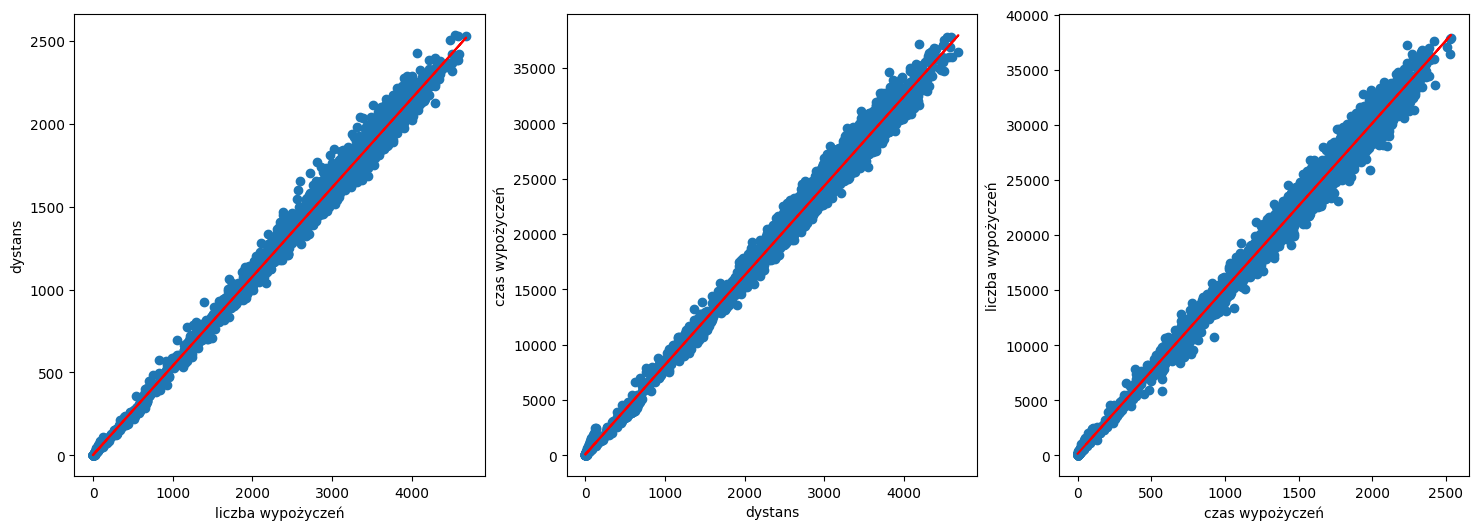

In [181]:
plt.figure(figsize=(18,6))
plt.subplot(1,3,1)
plt.scatter(x=bike_summary.loc[:,'distance'], y=bike_summary.loc[:,'rental_count'])
y_pred = calculate_regresion_line(bike_summary['distance'], bike_summary['rental_count'])
plt.plot(bike_summary['distance'], y_pred, color='red')
plt.xlabel('liczba wypożyczeń')
plt.ylabel('dystans')

plt.subplot(1,3,2)
plt.scatter(x=bike_summary['distance'], y=bike_summary['rental_time'])
y_pred = calculate_regresion_line(bike_summary['distance'], bike_summary['rental_time'])
plt.plot(bike_summary['distance'], y_pred, color='red')
plt.xlabel('dystans')
plt.ylabel('czas wypożyczeń')

plt.subplot(1,3,3)
plt.scatter(x=bike_summary['rental_count'], y=bike_summary['rental_time'])
y_pred = calculate_regresion_line(bike_summary['rental_count'], bike_summary['rental_time'])
plt.plot(bike_summary['rental_count'], y_pred, color='red')
plt.xlabel('czas wypożyczeń')
plt.ylabel('liczba wypożyczeń')

plt.show()

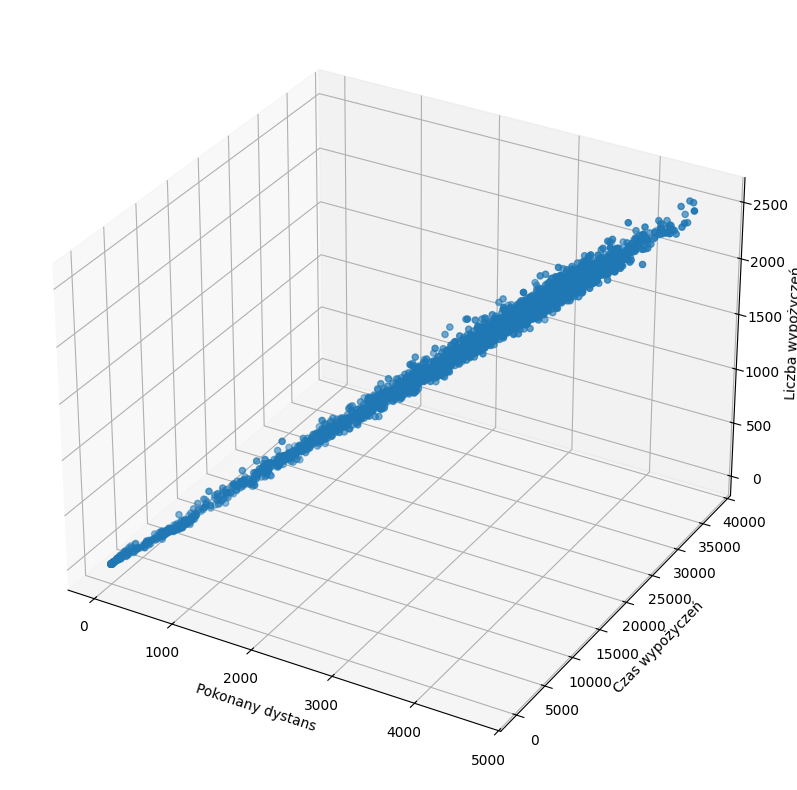

In [186]:
fig = plt.figure(figsize=(10,10))
ax = fig.add_subplot(projection='3d')
ax.scatter(bike_summary['distance'], bike_summary['rental_time'], bike_summary['rental_count'])
ax.set_xlabel('Pokonany dystans')
ax.set_ylabel('Czas wypożyczeń')
ax.set_zlabel('Liczba wypożyczeń')

plt.show()

#### Wykorzystanie stacji rowerowych

Histogramy wykazują prawostronną skośność, większość obserwacji gromadzi się po lewej stronie (większość wypożyczeń osiąga mniejsze statystyki niż wskazuje na to średnia.)

Po sporządzeniu wykresu słupkowego, okazuje się, że najpopularniejszymi stacjami wynajmu rowerów są:
- plac dominikański (galeria dominikańska)
- rondo reagana
- dworzec główny
- dworzec główny, południe
- rynek
- szczęśliwa (sky tower)
- powstańcow śląskich / aleja hallera
- wita stwosza / szewska
- legnicka (park magnolia)
- powstańców śląskich (arkady wrocławskie)

Tożsame statystyki uzyskaliśmy dla stacji zwrotu. Wynika z tego, że użytkownicy pokonują stałe trasy w jedną jak i w drugą strone. Może to wynikać ze szczytu porannego i wieczornego, gdzie użytkownicy najpierw w mniejszej liczbie docierają do pracy, uczelni, a następnie wracają do domów.

##### Wypożyczenia

In [253]:
station_rental_summary = bike_dataset5.groupby('rental_place').agg({
    'distance':     'sum',
    'rental_time':  'sum'
}).reset_index()
station_rental_summary['rental_count'] = bike_dataset5.groupby('rental_place').size().values

station_rental_summary

,rental_place,distance,rental_time,rental_count
0,3m,3980.714465,26195.27,1939
1,al. armii krajowej / bardzka,47016.377569,382149.06,25588
2,al. armii krajowej / borowska,80910.613441,593913.74,45980
3,al. armii krajowej / tarnogajska,16848.527353,144872.53,9311
4,al. brücknera / kwidzyńska,23618.708454,169393.69,9837
...,...,...,...,...
223,żernicka,8963.599050,59049.96,2583
224,żeromskiego / daszyńskiego,25489.539248,219445.21,14628
225,żeromskiego / kluczborska,16881.521421,147837.81,10389
226,żmigrodzka / broniewskiego,39861.510685,316026.44,18769


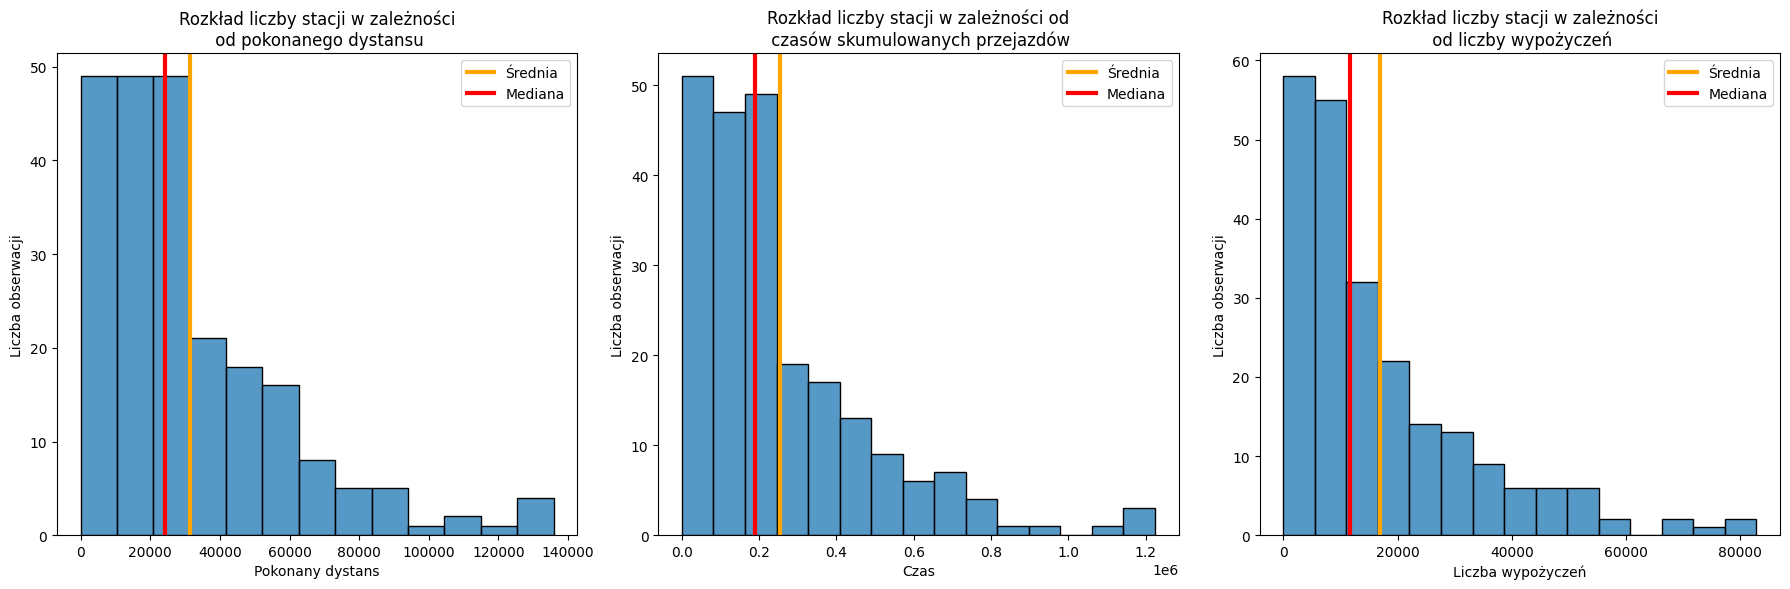

In [245]:
plt.figure(figsize=(18,6))
plt.subplot(1,3,1)
sns.histplot(data=station_rental_summary, x='distance').set(ylabel='Liczba obserwacji', xlabel='Pokonany dystans')
plt.axvline(station_rental_summary['distance'].mean(), c='orange', lw=3, label='Średnia')
plt.axvline(station_rental_summary['distance'].median(), c='red', lw=3, label='Mediana')
plt.title('Rozkład liczby stacji w zależności\n od pokonanego dystansu')
plt.legend()

plt.subplot(1,3,2)
sns.histplot(data=station_rental_summary, x='rental_time').set(ylabel='Liczba obserwacji', xlabel='Czas')
plt.axvline(station_rental_summary['rental_time'].mean(), c='orange', lw=3, label='Średnia')
plt.axvline(station_rental_summary['rental_time'].median(), c='red', lw=3, label='Mediana')
plt.title('Rozkład liczby stacji w zależności od\n czasów skumulowanych przejazdów')
plt.legend()

plt.subplot(1,3,3)
sns.histplot(data=station_rental_summary, x='rental_count').set(ylabel='Liczba obserwacji', xlabel='Liczba wypożyczeń')
plt.axvline(station_rental_summary['rental_count'].mean(), c='orange', lw=3, label='Średnia')
plt.axvline(station_rental_summary['rental_count'].median(), c='red', lw=3, label='Mediana')
plt.title('Rozkład liczby stacji w zależności\n od liczby wypożyczeń')
plt.legend()

plt.tight_layout()
plt.show()

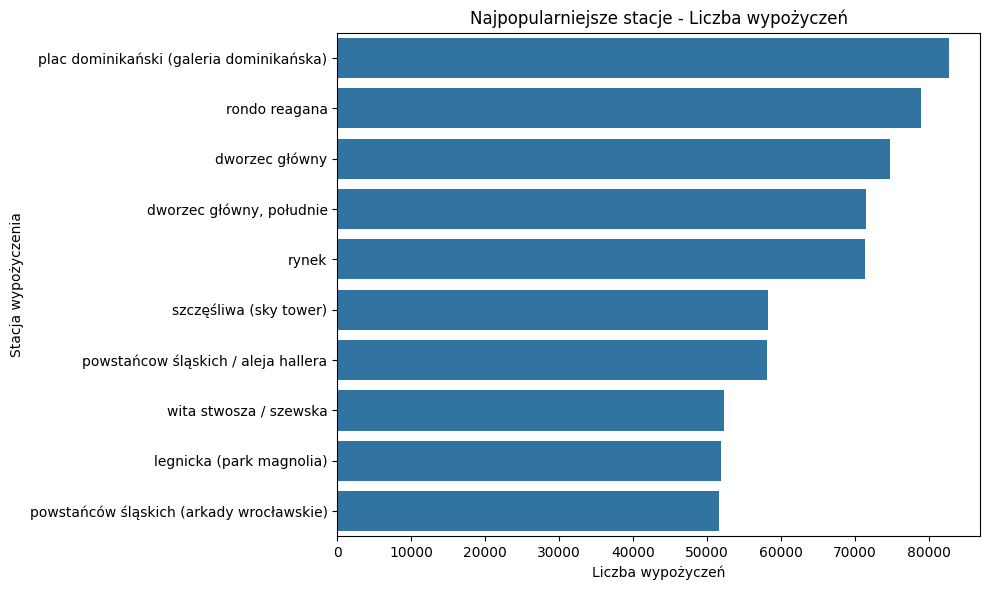

In [250]:
top_station_rental = station_rental_summary.nlargest(10, 'rental_count')

plt.figure(figsize=(10,6))

sns.barplot(x='rental_count', y='rental_place',
            data=top_station_rental, orient='h',
            order=top_station_rental['rental_place']).set(
                xlabel='Liczba wypożyczeń',
                ylabel='Stacja wypożyczenia'
            )
plt.title('Najpopularniejsze stacje wypożyczenia - Liczba wypożyczeń')

plt.tight_layout()
plt.show()

##### Zwroty

In [256]:
station_return_summary = bike_dataset5.groupby('rental_place').agg({
    'distance':     'sum',
    'rental_time':  'sum'
}).reset_index()
station_return_summary['rental_count'] = bike_dataset5.groupby('rental_place').size().values

station_return_summary

,rental_place,distance,rental_time,rental_count
0,3m,3980.714465,26195.27,1939
1,al. armii krajowej / bardzka,47016.377569,382149.06,25588
2,al. armii krajowej / borowska,80910.613441,593913.74,45980
3,al. armii krajowej / tarnogajska,16848.527353,144872.53,9311
4,al. brücknera / kwidzyńska,23618.708454,169393.69,9837
...,...,...,...,...
223,żernicka,8963.599050,59049.96,2583
224,żeromskiego / daszyńskiego,25489.539248,219445.21,14628
225,żeromskiego / kluczborska,16881.521421,147837.81,10389
226,żmigrodzka / broniewskiego,39861.510685,316026.44,18769


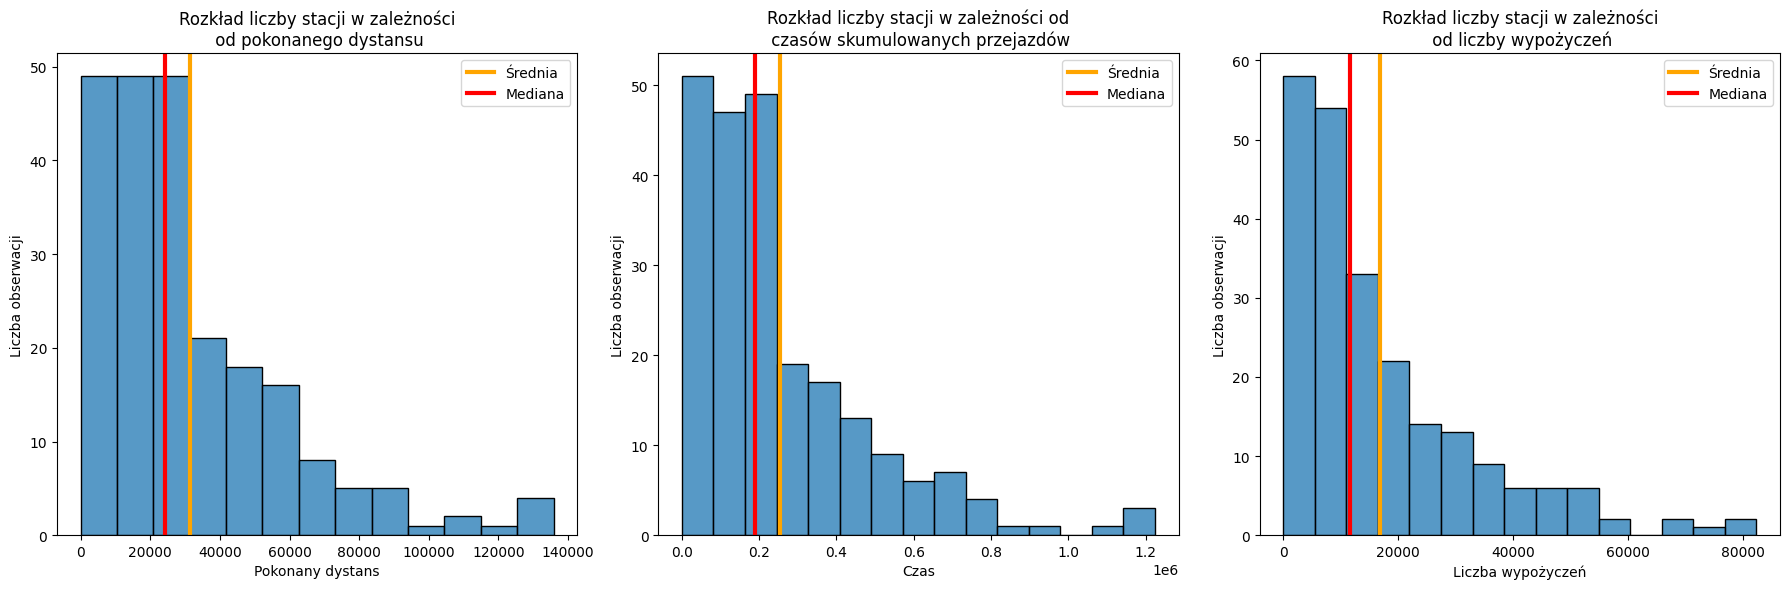

In [257]:
plt.figure(figsize=(18,6))
plt.subplot(1,3,1)
sns.histplot(data=station_return_summary, x='distance').set(ylabel='Liczba obserwacji', xlabel='Pokonany dystans')
plt.axvline(station_return_summary['distance'].mean(), c='orange', lw=3, label='Średnia')
plt.axvline(station_return_summary['distance'].median(), c='red', lw=3, label='Mediana')
plt.title('Rozkład liczby stacji w zależności\n od pokonanego dystansu')
plt.legend()

plt.subplot(1,3,2)
sns.histplot(data=station_return_summary, x='rental_time').set(ylabel='Liczba obserwacji', xlabel='Czas')
plt.axvline(station_return_summary['rental_time'].mean(), c='orange', lw=3, label='Średnia')
plt.axvline(station_return_summary['rental_time'].median(), c='red', lw=3, label='Mediana')
plt.title('Rozkład liczby stacji w zależności od\n czasów skumulowanych przejazdów')
plt.legend()

plt.subplot(1,3,3)
sns.histplot(data=station_return_summary, x='rental_count').set(ylabel='Liczba obserwacji', xlabel='Liczba wypożyczeń')
plt.axvline(station_return_summary['rental_count'].mean(), c='orange', lw=3, label='Średnia')
plt.axvline(station_return_summary['rental_count'].median(), c='red', lw=3, label='Mediana')
plt.title('Rozkład liczby stacji w zależności\n od liczby wypożyczeń')
plt.legend()

plt.tight_layout()
plt.show()

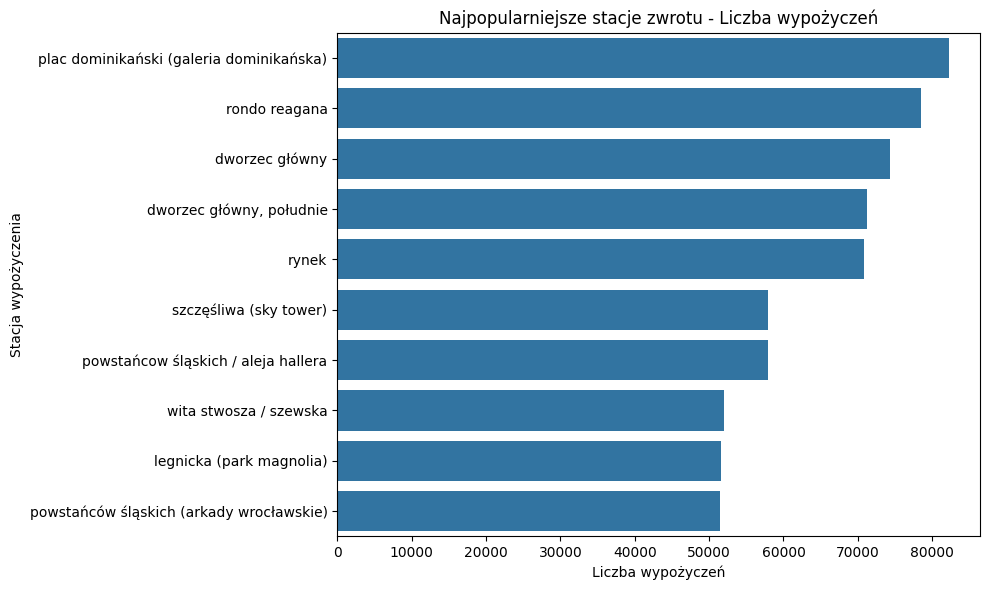

In [258]:
top_station_return = station_return_summary.nlargest(10, 'rental_count')

plt.figure(figsize=(10,6))

sns.barplot(x='rental_count', y='rental_place',
            data=top_station_return, orient='h',
            order=top_station_return['rental_place']).set(
                xlabel='Liczba wypożyczeń',
                ylabel='Stacja wypożyczenia'
            )
plt.title('Najpopularniejsze stacje zwrotu - Liczba wypożyczeń')

plt.tight_layout()
plt.show()

## Wizualizacja i analiza przestrzenna

#### Map populatność

In [ ]:
station_count = bike_dataset4.iloc[:,4:6]
station_count = station_count.groupby(['Stacja wynajmu', 'Stacja zwrotu']).size().reset_index(name='Ilość wystąpień')

station_count = station_count.merge(
    locations[['Station', 'Latitude', 'Longitude']],
    left_on=['Stacja wynajmu'],
    right_on=['Station'],
    how='left'
    )

station_count = station_count.merge(
    locations[['Station', 'Latitude', 'Longitude']],
    left_on=['Stacja zwrotu'],
    right_on=['Station'],
    how='left')

station_count.drop(station_count.columns[[3,6]], inplace=True, axis=True)
station_count.columns = ['Stacja_wynajmu', 'Stacja_zwrotu', 'Ilość_wystąpień', 'Latitude_wynajmu', 'Longitude_wynajmu', 'Latitude_zwrotu', 'Longitude_zwrotu']
# popular_trips = station_count.sort_values('Ilość_wystąpień', ascending=False).head(50)
popular_trips = station_count[station_count.iloc[:,2]>=100]

In [ ]:
import folium
m = folium.Map(location=(lat_center, lon_center), zoom_start=12)

for trip in popular_trips.itertuples():
    _, start, end, *_, lat_start, lon_start, lat_end, lon_end = trip
    folium.PolyLine(
        locations=[(lat_start, lon_start), (lat_end, lon_end)],
        # color='blue',
        # weight=2,
        opacity=0.6
    ).add_to(m)
    
    folium.Marker(
        location=(lat_start, lon_start),
        tooltip=start,
        icon=folium.Icon(color='blue')
    ).add_to(m)
    
    folium.Marker(
        location=(lat_end, lon_end),
        tooltip=end,
        icon=folium.Icon(color='red')
    ).add_to(m)
    
m

#### Map statystyki

In [ ]:
agg_data = bike_dataset4.groupby(['Stacja wynajmu']).agg({
    'UID wynajmu': 'count',  # Liczba wypożyczeń
    'Czas': 'mean',  # Średni czas wypożyczenia
    'Odległość': 'mean',  # Średnia odległość
    'Prędkość': 'mean',  # Średnia prędkość
}).reset_index()

agg_data.columns = ['Station', 'Rentals', 'Avg Time', 'Avg Distance', 'Avg Speed']

In [ ]:
import folium
from folium.plugins import MarkerCluster

def create_tooltip(row):
    text = f"""
    Stacja: {row['Station']}</br>
    Liczba wypożyczeń: {row['Rentals']}</br>
    Średni czas: {row['Avg Time']:.2f} min</br>
    Średnia odległość: {row['Avg Distance']:.2f} km</br>
    Średnia prędkość: {row['Avg Speed']:.2f} km/h
    """
    return text

def station_color(row, arg, limit):
    if row[arg]<limit[0]: return 'green'
    elif row[arg]<limit[1]: return 'orange'
    else: return 'red'

def create_map(arg, limit):
    m = folium.Map(location=(lat_center, lon_center), zoom_start=12)
    # marker_cluster = MarkerCluster().add_to(m)
    for loc in locations.itertuples():
        # Sprawdzamy, czy są dane dla tej stacji w danym dniu
        station_data = agg_data[agg_data['Station'] == loc[1]]
        if not station_data.empty:
            row = station_data.iloc[0]
            folium.Marker(
                location=(loc[2], loc[3]),
                tooltip=create_tooltip(row),
                icon=folium.Icon(color=station_color(row, arg, limit)),
            ).add_to(m)

    return m

In [ ]:
create_map('Avg Speed', [9,10])

In [ ]:
create_map('Avg Time', [13,15])

In [ ]:
create_map('Avg Distance', [2,2.5])

#### Grafy
Skonstrujemy graf nieskierowany (albo i skierowany), który ukaże nam w wizualnej formie i połączenia między najpopularniejszymi stacjami.

Stosując algorytm ***Louvain community finder*** jesteśmy w stanie pogrupować stacje. Metoda dołącza kolejne węzły do danej grupie i oblicza tz. modularność. Przyjmuje ona wartości od -1 do 1. Zależy nam, żeby uzyskać jak największą wartość. Wydaje się podobna do k-means, tylko że zamiast zmniejszać różnorodność, zwiększa modularność. To tak jak hierarchiczne.

Jak można zauważyć, automatycznie wykrywa ile grup utworzyć. (Znaleźć odpowiedni opis metody)

#### Klastrowanie KMeans
Bazując na klastrowaniu itercyjno-optymalizacyjnym nie uzyskujemu znaczących różnic pomiędzy grupanie w statystykach dotyczących prędkości, czasu przejazdu oraz pokonanego dystansu. Może czegoś dowiemy się z wykresu pudełkowego?

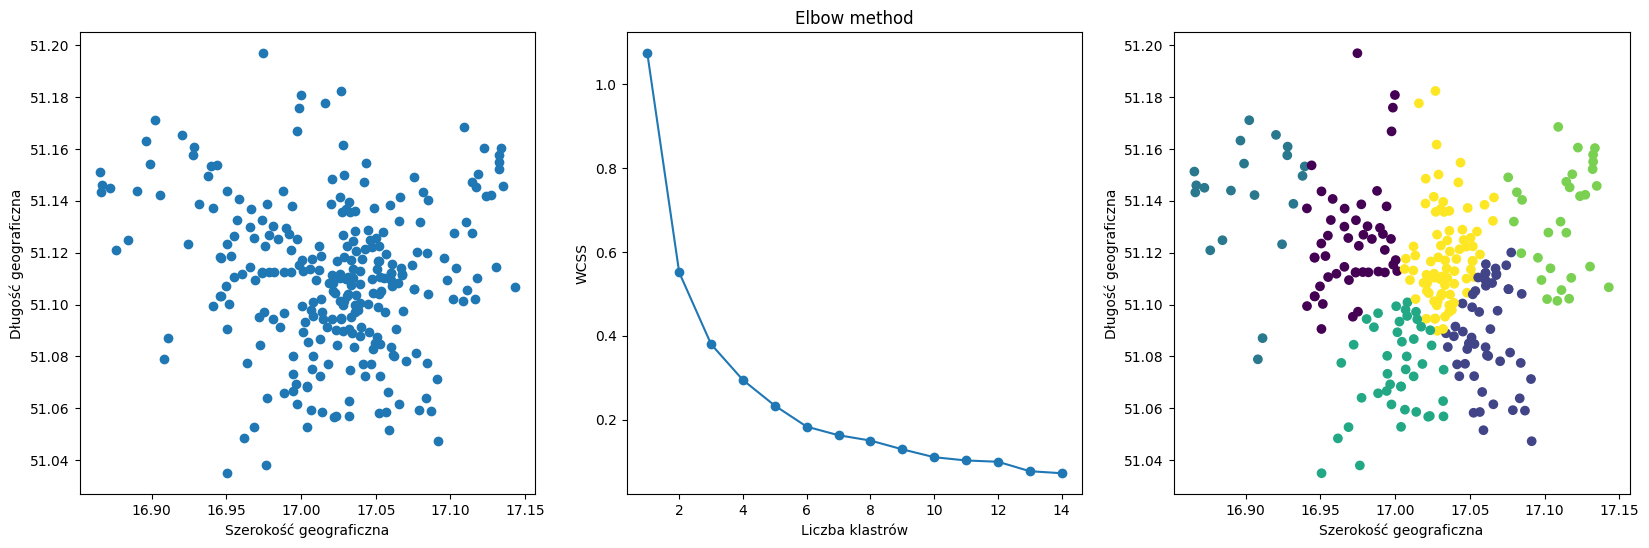

In [304]:
from matplotlib import pyplot as plt
from sklearn.cluster import KMeans

plt.figure(figsize=(20,6))

plt.subplot(1,3,1)
plt.scatter(locations.iloc[:,2], locations.iloc[:,1])
plt.ylabel('Długość geograficzna')
plt.xlabel('Szerokość geograficzna')


WCSS = []
for i in range(1, 15):
    kmeans = KMeans(n_clusters=i)
    kmeans.fit(locations.iloc[:,[1,2]])
    WCSS.append(kmeans.inertia_)
    
plt.subplot(1,3,2)
plt.plot(range(1,15), WCSS, marker='o')
plt.title('Elbow method')
plt.xlabel('Liczba klastrów')
plt.ylabel('WCSS')


plt.subplot(1,3,3)
kmeans = KMeans(n_clusters=6)
kmeans.fit(locations.iloc[:,[1,2]])

plt.scatter(locations.iloc[:,2], locations.iloc[:,1], c=kmeans.labels_)
plt.ylabel('Długość geograficzna')
plt.xlabel('Szerokość geograficzna')

plt.show()

In [321]:
locations2 = locations.copy()
locations2['kmeans'] = kmeans.labels_

bike_dataset6 = bike_dataset5.merge(
    locations2[['Station', 'kmeans']],
    left_on=['rental_place'],
    right_on=['Station'],
    how='left'
    )
bike_dataset6.drop('Station', inplace=True, axis=True)
bike_dataset6.iloc[:,[7,8,9,10,14]].groupby('kmeans').describe().T

kmeans                         0              1             2              3  \
rental_time count  409105.000000  816657.000000  50519.000000  669819.000000   
            mean       16.386153      15.266662     16.954141      14.958595   
            std        16.500736      15.856577     19.175934      14.701882   
            min         0.280000       0.300000      1.070000       0.400000   
            25%         7.600000       7.680000      7.280000       7.630000   
            50%        12.180000      11.550000     10.380000      11.630000   
            75%        18.120000      16.650000     17.480000      16.650000   
            max       179.930000     180.000000    179.720000     179.900000   
distance    count  409105.000000  816657.000000  50519.000000  669819.000000   
            mean        2.142560       1.811820      2.342948       2.009344   
            std         1.483562       1.139158      2.152204       1.233742   
            min         0.230533       0.001344      0.308030       0.280307   
            25%         1.042219       1.026130      1.135189       1.130365   
            50%         1.804417       1.584581      1.436212       1.771732   
            75%         2.827401       2.290456      2.588987       2.542580   
            max        14.129742      15.133724     18.178474      15.358346   
speed       count  409105.000000  816657.000000  50519.000000  669819.000000   
            mean        9.266144       8.642101      9.790073       9.534842   
            std         3.356537       3.177608      3.525400       3.208584   
            min         0.079494       0.001671      0.147736       0.097284   
            25%         7.323820       6.769275      7.927576       7.716636   
            50%         9.383648       8.717970     10.017781       9.672820   
            75%        11.382413      10.659496     11.935284      11.591982   
            max        49.518193      49.943002     43.466254      49.404358   

kmeans                         4             5  
rental_time count  132255.000000  1.765022e+06  
            mean       18.084738  1.448623e+01  
            std        18.667720  1.484574e+01  
            min         0.470000  1.200000e-01  
            25%         7.430000  7.430000e+00  
            50%        12.720000  1.113000e+01  
            75%        19.700000  1.608000e+01  
            max       179.820000  1.800000e+02  
distance    count  132255.000000  1.765022e+06  
            mean        2.303894  1.709510e+00  
            std         1.736209  1.120265e+00  
            min         0.253452  9.442290e-02  
            25%         1.048420  9.573854e-01  
            50%         1.696823  1.450186e+00  
            75%         3.088307  2.170747e+00  
            max        17.517828  1.409897e+01  
speed       count  132255.000000  1.765022e+06  
            mean        9.149924  8.386566e+00  
            std         3.395455  3.057989e+00  
            min         0.088065  3.301885e-02  
            25%         7.097915  6.593824e+00  
            50%         9.329533  8.492543e+00  
            75%        11.424924  1.033637e+01  
            max        49.357137  4.998471e+01

#### Odległość od centrum

In [ ]:
locations2 = locations.copy()
lat_center = locations['Latitude'].mean()
lon_center = locations['Longitude'].mean()

locations2['to_center'] = locations2.apply(lambda row: haversine(row['Latitude'], row['Longitude'], lat_center, lon_center), axis=1)

def classify(dist):
    return 'centrum' if dist<=3 else 'przedmieścia' if dist<=7 else 'obrzeża'

locations2['class'] = locations2.apply(lambda row: classify(row['to_center']), axis=1)
locations2['class_numeric'] = locations2['class'].map({'centrum': 1, 'przedmieścia': 2, 'obrzeża': 3})

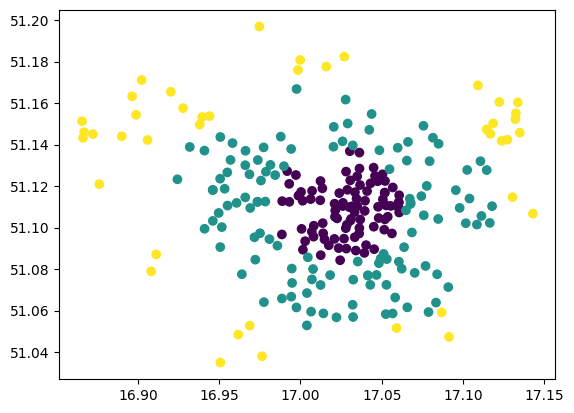

In [ ]:
plt.scatter(locations2.iloc[:,2], locations2.iloc[:,1], c=locations2['class_numeric'])
plt.show()

In [ ]:
bike_dataset4 = bike_dataset3.merge(
    locations2[['Station', 'class']],
    left_on=['Stacja wynajmu'],
    right_on=['Station'],
    how='left'
    )

bike_dataset4.drop('Station', inplace=True, axis=True)
bike_dataset4.iloc[:,6:10].groupby('class').describe().transpose()

class                  centrum      obrzeża  przedmieścia
Czas      count  147934.000000  6254.000000  75205.000000
          mean       17.173837    22.511319     19.538179
          std       112.600514    93.143715     77.920378
          min         0.200000     0.700000      0.300000
          25%         7.700000     7.450000      8.380000
          50%        11.430000    12.400000     12.800000
          75%        16.250000    20.650000     18.470000
          max     31111.580000  6109.250000  11269.250000
Odległość count  147934.000000  6254.000000  75205.000000
          mean        1.750115     2.604918      2.204190
          std         1.102481     2.172769      1.405479
          min         0.094423     0.253452      0.242032
          25%         0.992852     1.118393      1.193888
          50%         1.520795     1.968149      1.905920
          75%         2.221404     3.233517      2.853404
          max        14.018749    16.576503     15.849780
Prędkość  count  147934.000000  6254.000000  75205.000000
          mean        8.466524    10.019767      9.290851
          std         3.404590    10.447303      3.866265
          min         0.003150     0.047960      0.003862
          25%         6.666118     7.933825      7.339674
          50%         8.537339    10.159137      9.427938
          75%        10.395866    12.261837     11.450146
          max       270.744060   760.259452    289.633363

In [269]:
popular_trace = bike_dataset5.groupby(['rental_place', 'return_place']).size().reset_index(name='rentals')

In [270]:
popular_trace.nlargest(10, 'rentals')

,rental_place,return_place,rentals
25195,powstańcow śląskich / aleja hallera,aleja hallera / mielecka,5477
11410,"kosmonautów / fieldorfa, szpital wojewódzki",wojanowska / arbuzowa,5307
5189,dyrekcyjna / borowska (wroclavia),al. armii krajowej / borowska,4979
27544,rondo reagana,nowowiejska / wyszyńskiego,4939
1723,aleja hallera / mielecka,powstańcow śląskich / aleja hallera,4635
27569,rondo reagana,plac grunwaldzki (ds ołówek),4574
32343,wojanowska / arbuzowa,"kosmonautów / fieldorfa, szpital wojewódzki",4464
274,al. armii krajowej / borowska,dyrekcyjna / borowska (wroclavia),4424
5026,"dworzec główny, południe",hubska / prudnicka,4391
6835,grabiszyńska / stalowa,grabiszyńska / aleja hallera,4268


Graf przedstawiający 100 najczęściej pokonywanych tras.

In [271]:
from pyvis.network import Network
import community as community_louvain
import networkx as nx

G = nx.from_pandas_edgelist(popular_trace.nlargest(100, 'rentals'),
                            source='rental_place',
                            target='return_place',
                            edge_attr='rentals')

communities = community_louvain.best_partition(G)

nx.set_node_attributes(G, dict(G.degree), 'size')
nx.set_node_attributes(G, communities, 'group')

com_net = Network(notebook=True, cdn_resources='in_line', height='1200px', width='100%')
com_net.from_nx(G)

with open('bikes_plot_1.html', 'w', encoding='utf-8') as f:
    f.write(com_net.generate_html())

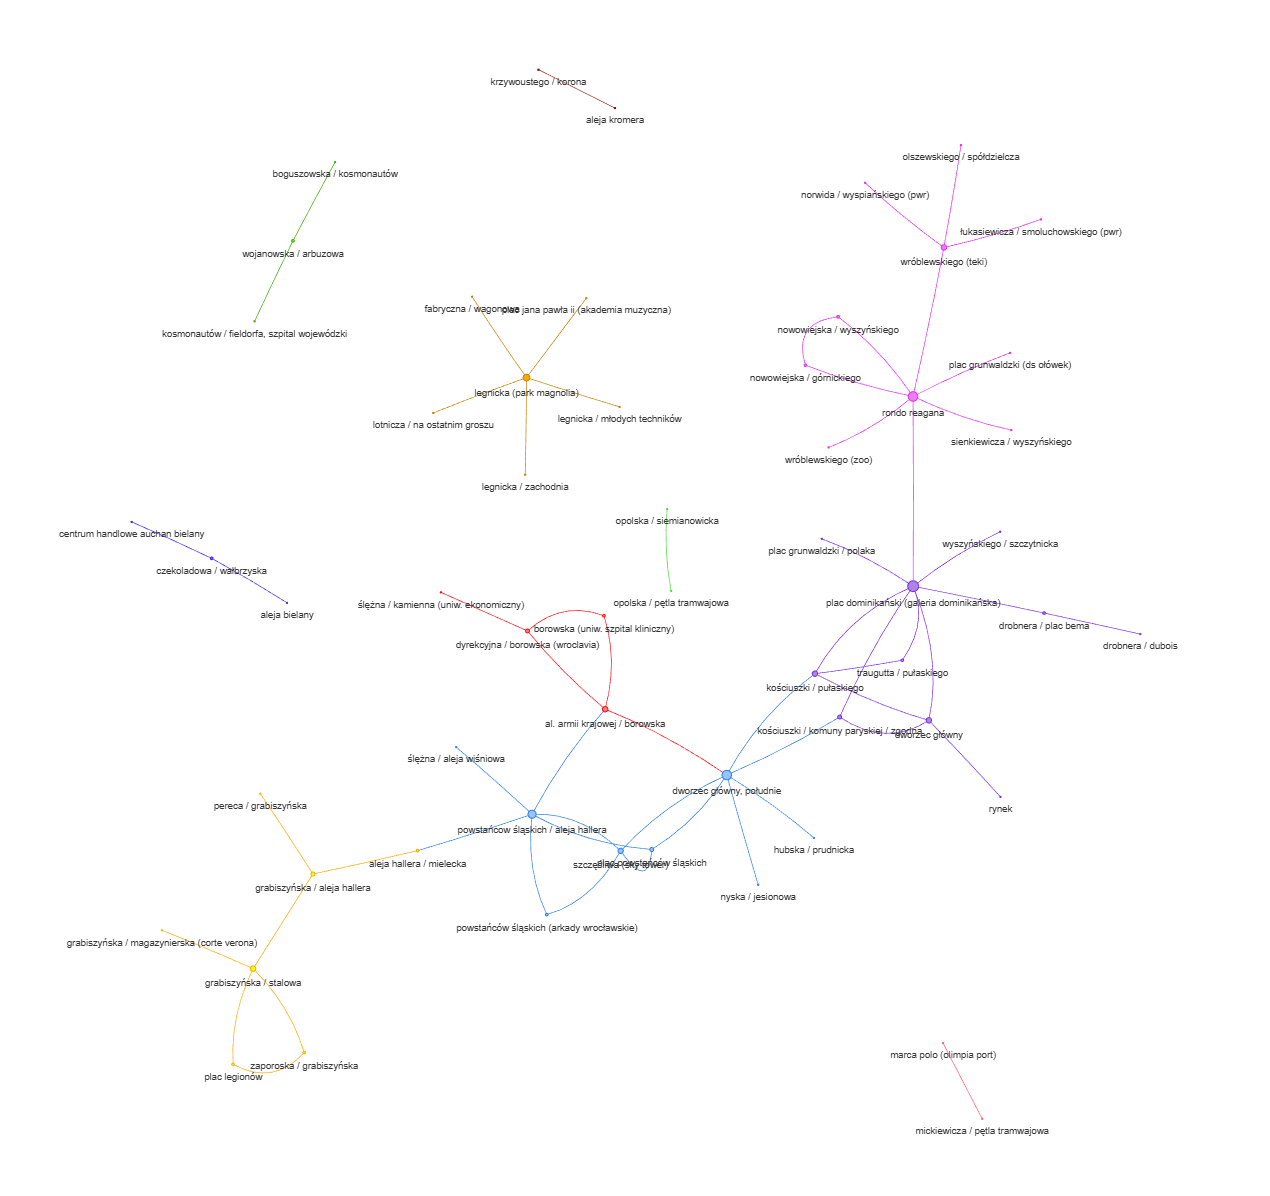

Graf prezentujący trasy o co najmniej 1000 wypożyczeń.

In [272]:
from pyvis.network import Network
import community as community_louvain
import networkx as nx

G = nx.from_pandas_edgelist(popular_trace[popular_trace['rentals']>=1000],
                            source='rental_place',
                            target='return_place',
                            edge_attr='rentals')

communities = community_louvain.best_partition(G)

nx.set_node_attributes(G, dict(G.degree), 'size')
nx.set_node_attributes(G, communities, 'group')

com_net = Network(notebook=True, cdn_resources='in_line', height='1200px', width='100%')
com_net.from_nx(G)
com_net.set_options("""
const options = {
  "nodes": {
    "font": {
      "size": 30
    }
  },
  "physics": {
    "forceAtlas2Based": {
      "springLength": 100
    },
    "solver": "forceAtlas2Based"
  }
}""")

with open('bikes_plot_2.html', 'w', encoding='utf-8') as f:
    f.write(com_net.generate_html())

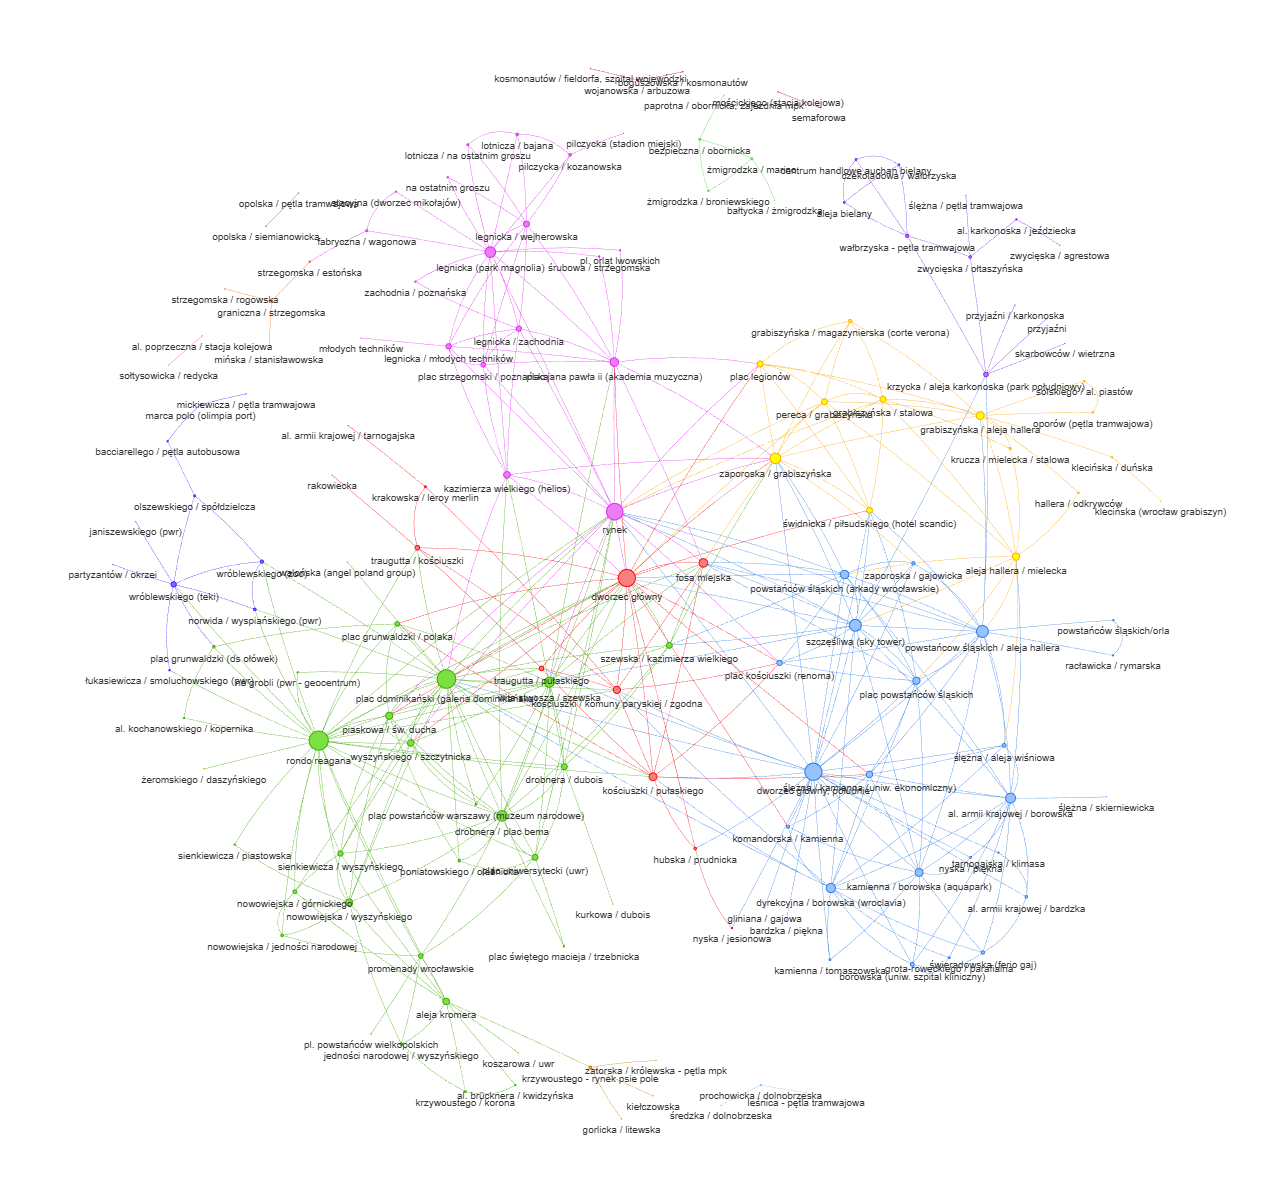

Zobaczmy jak ta metoda klasyfikacji przełożyła się na położenie geograficzne

In [294]:
bike_class = pd.DataFrame(list(communities.items()), columns=['Station', 'class']).merge(locations, how='left', on='Station')
bike_class

,Station,class,Latitude,Longitude
0,al. armii krajowej / bardzka,2,51.082830,17.048240
1,al. armii krajowej / borowska,2,51.083610,17.035230
2,tarnogajska / klimasa,2,51.080150,17.062280
3,świeradowska (ferio gaj),2,51.076920,17.041439
4,aleja hallera / mielecka,1,51.089315,17.001501
...,...,...,...,...
142,partyzantów / okrzei,7,51.109457,17.097924
143,łukasiewicza / smoluchowskiego (pwr),7,51.108288,17.064884
144,ślężna / pętla tramwajowa,6,51.072302,17.012384
145,średzka / dolnobrzeska,5,51.145970,16.866920


In [292]:
bike_class.groupby('class').size()

class
0      5
1     14
2     37
3      3
4     23
5      3
6     12
7     36
8      2
9      2
10     4
11     2
12     4
dtype: int64

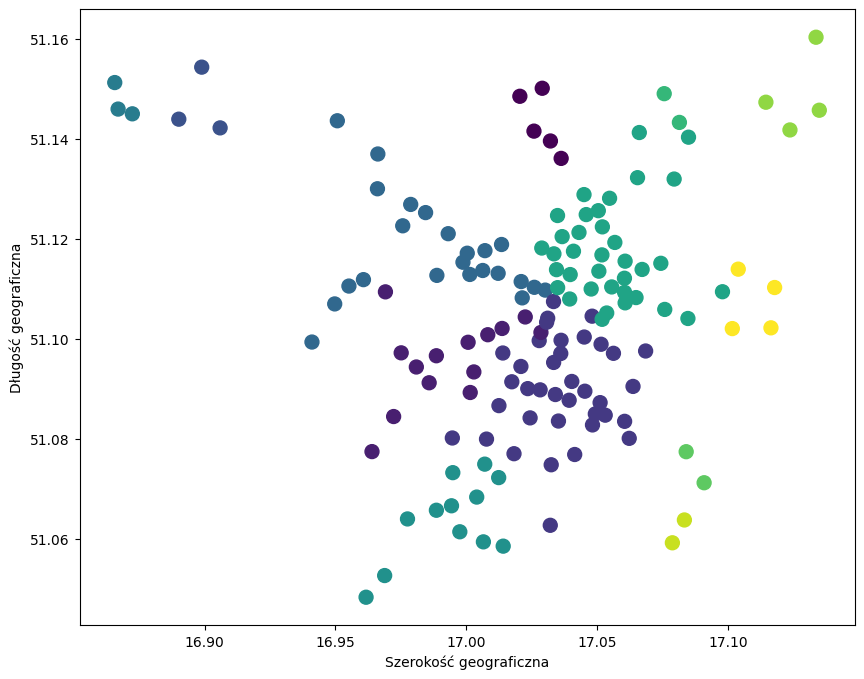

In [293]:
plt.figure(figsize=(10,8))
plt.scatter(y=bike_class['Latitude'], x=bike_class['Longitude'], c=bike_class['class'], s=100)
plt.ylabel('Długość geograficzna')
plt.xlabel('Szerokość geograficzna')
plt.show()

## Predykcja szeregu czasowego

#### ARIMA
Model działający wyłącznie na poprzednich wartościach szeregu.

Składa się z części AR - autoregresyjnej, I - inteligents, MA - średniej kroczącej

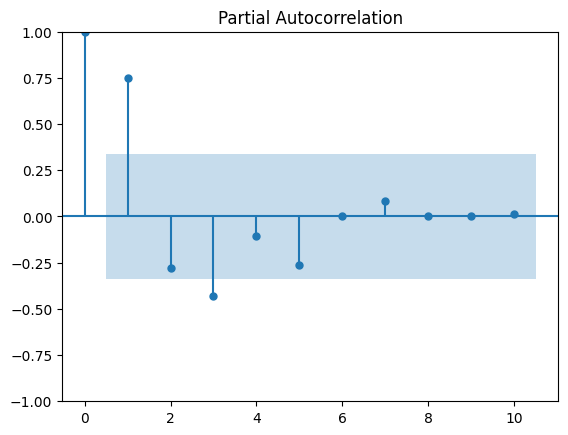

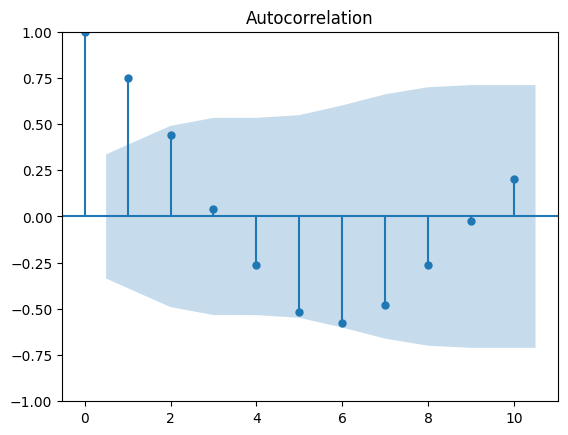

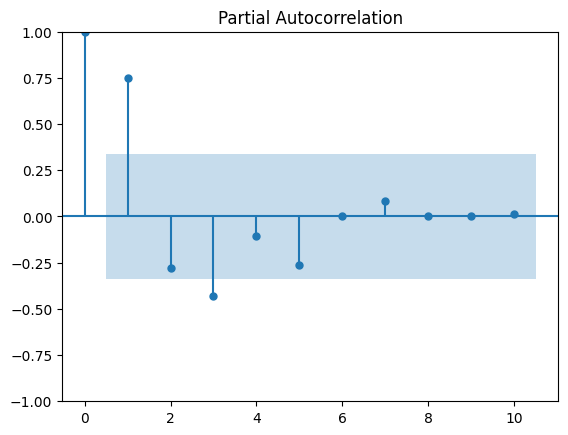

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
plot_acf(bike_number, lags=10)
plot_pacf(bike_number, lags=10)
# plt.show()

In [ ]:
from statsmodels.tsa.stattools import adfuller

result = adfuller(bike_number)
print('ADF Statistic: %f' % result[0])
print('p-value: %f' % result[1])

ADF Statistic: -4.868176
p-value: 0.000040


In [ ]:
from statsmodels.tsa.arima.model import ARIMA

model = ARIMA(bike_number, order=(1, 1, 1))
model_fit = model.fit()
forecast = model_fit.get_forecast(steps=10)

c:\Users\bereZi\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\bereZi\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\bereZi\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


c:\Users\bereZi\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\bereZi\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\bereZi\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\bereZi\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


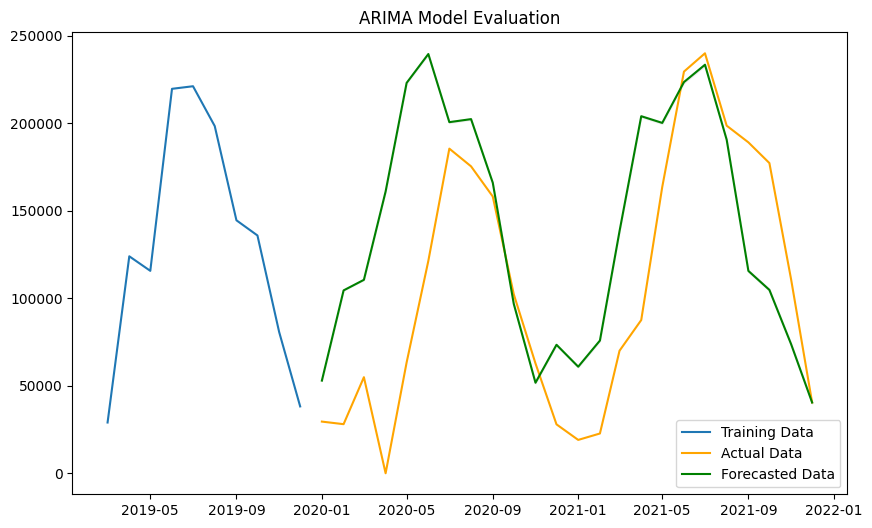

In [ ]:
from sklearn.metrics import mean_squared_error

# Split the data into train and test
train_size = int(len(bike_number) * 0.3)
train, test = bike_number[0:train_size], bike_number[train_size:len(bike_number)]

# Fit the ARIMA model on the training dataset
model_train = ARIMA(train, order=(5, 1, 2))
model_train_fit = model_train.fit()

# Forecast on the test dataset
test_forecast = model_train_fit.get_forecast(steps=len(test))
test_forecast_series = pd.Series(test_forecast.predicted_mean, index=test.index)

# Calculate the mean squared error
mse = mean_squared_error(test, test_forecast_series)
rmse = mse**0.5

# Create a plot to compare the forecast with the actual test data
plt.figure(figsize=(10,6))
plt.plot(train, label='Training Data')
plt.plot(test, label='Actual Data', color='orange')
plt.plot(test_forecast_series, label='Forecasted Data', color='green')
plt.fill_between(test.index, 
                 test_forecast.conf_int().iloc[:, 0], 
                 test_forecast.conf_int().iloc[:, 1], 
                 color='k', alpha=.05)
plt.title('ARIMA Model Evaluation')
plt.legend()
plt.show()

#### SARIMA
Model uwzględniający wahania sezonowe.

#### SARIMAX
Zyskujemy możliwość wykorzystania dodatkowych zmiennych. Na przykład czy była pandemia, danych pogodowych.

#### LSTM